# Tech Launch Hype Predictor
### Identifying Genuine Market Demand from Initial Launch Buzz

**Student:** Isha Sri Prakash  
**Register Number:** CB.SC.U4CSE23029  
**Class/Section:** CSE A  
**Course:** Business Analytics — Individual Case Study  
**Business Domain:** Technology & Product Marketing

---

### How to use this notebook

Run the sections in order. The notebook is structured to mirror the required report format.

| Section | Report Section |
|---|---|
| 0–1 | Problem Statement and Objectives |
| 2 | Data Collection and Dataset Description |
| 3 | Data Preparation and Exploratory Analysis |
| 4 | Analytics Method and Implementation |
| 5 | Comparison with State-of-the-Art Methods |
| 6 | Results, Business Insights and Recommendations |
| 7 | Conclusion and References |

> ### READ THIS BEFORE SUBMITTING
>
> Section 2 contains **real, working scrapers** for Google Trends, Reddit and retailer
> pages. They are the deliverable — your assignment requires data *you* collected.
>
> Section 2.5 also contains a **synthetic data generator**. It exists only so the rest of
> the notebook runs end-to-end while you are still setting up API credentials.
> **Synthetic data is not submittable.** Set `USE_SYNTHETIC_DATA = False`, run the real
> collectors, and re-run everything before you commit.
>
> Sections 5 and 7 are deliberately left as templates. Do not submit fabricated
> citations — find the three papers yourself and fill the table in.

---
## 0. Environment Setup

In [1]:
# Run once. Skip if already installed.
# !pip install pandas numpy matplotlib seaborn scikit-learn scipy pytrends praw requests beautifulsoup4 lxml tqdm

In [2]:
import os
import json
import time
import warnings
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")

# ----------------------------- Reproducibility -----------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ----------------------------- Project paths -------------------------------
ROOT       = Path(".")
DATA_DIR   = ROOT / "data"
RAW_DIR    = DATA_DIR / "raw"
PROC_DIR   = DATA_DIR / "processed"
FIG_DIR    = ROOT / "figures"
OUT_DIR    = ROOT / "outputs"

for d in (RAW_DIR, PROC_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------- Study design --------------------------------
OBS_WEEKS        = 26   # total observation window per product (6 months)
FEATURE_WEEKS    = 4    # weeks 1-4 post-launch -> predictors ONLY
LABEL_START_WEEK = 20   # weeks 21-26 -> outcome window ONLY
LABEL_END_WEEK   = 26

# Labelling thresholds (from the approved proposal)
SUSTAINED_MAX_DECAY = 0.50   # decay < 50%  -> sustained demand
COLLAPSE_MIN_DECAY  = 0.75   # decay > 75%  -> hype collapse
                             # 50%-75%      -> ambiguous, resolved in Section 3.4

# ----------------------------- Plot styling --------------------------------
plt.rcParams.update({
    "figure.figsize":  (10, 5),
    "figure.dpi":      110,
    "savefig.dpi":     200,
    "savefig.bbox":    "tight",
    "axes.grid":       True,
    "grid.alpha":      0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size":       10,
    "axes.titlesize":  12,
    "axes.titleweight": "bold",
})

PALETTE = {"sustained": "#2A9D8F", "collapse": "#E76F51", "neutral": "#264653"}

print("Environment ready.")
print(f"Predictors drawn from weeks 1-{FEATURE_WEEKS}")
print(f"Outcome measured over weeks {LABEL_START_WEEK+1}-{LABEL_END_WEEK}")

Environment ready.
Predictors drawn from weeks 1-4
Outcome measured over weeks 21-26


---
## 1. Problem Statement and Objectives

### 1.1 Business Problem

Tech companies and investors routinely fail to separate **viral launch excitement** from
**sustainable market demand**. Launches such as Vision Pro, Humane AI Pin and Rabbit R1
produced enormous initial media coverage and social engagement, yet search interest and
consumer demand collapsed within months. Other products showed flatter launch peaks but
steadily growing adoption, indicating genuine product–market fit.

The cost of this confusion is spread across the ecosystem:

- **Investors** commit capital to products with ephemeral appeal.
- **Startups** misallocate engineering and marketing budget toward hype maintenance
  instead of retention and growth.
- **Retailers** stock inventory destined for rapid markdown.
- **Marketing teams** overspend on campaigns for products with no long-term viability.

The core difficulty is *timing*. Launch-day metrics — trending posts, first-week sales
spikes, review volume — are **misleading indicators of longevity**. A product that looks
successful on Day 1 may be dead by Month 6, but by the time that is visible the money is
already spent. There is currently no systematic, data-driven early-warning method that
works soon enough to change a decision.

### 1.2 Analytical Framing

This case study reframes the business problem as a **binary classification task with a
strict temporal separation** between predictors and outcome:

$$
\underbrace{X = f(\text{weeks } 1\text{–}4)}_{\text{observed early}}
\;\longrightarrow\;
\underbrace{y \in \{\text{sustained},\ \text{hype collapse}\}}_{\text{measured at months } 5\text{–}6}
$$

Every predictor is computed **only** from the first four weeks after launch. The label is
computed **only** from weeks 21–26. No information from the outcome window is allowed into
the feature set. This separation is what makes the model a genuine early-warning system
rather than a retrospective description, and it is verified programmatically in Section 3.5.

### 1.3 Objectives

1. **Identify early signals of demand sustainability.** Collect publicly available
   behavioural metrics (Google search interest, Reddit engagement, retail price and
   availability) for weeks 1–4 post-launch and test which of them carry predictive
   information about month 6 viability.

2. **Classify launches by hype decay pattern.** Build and evaluate a supervised
   classifier that separates *sustained demand* from *hype collapse*, and report
   performance using metrics appropriate to the business cost of each error type.

3. **Enable early intervention.** Convert the model output into a Week-4 risk score that
   investors, product teams and retailers can act on before sunk costs accumulate.

### 1.4 Cost Asymmetry (drives metric choice)

The two errors are not equally expensive, so accuracy alone is a poor objective:

| Error | Meaning | Business consequence |
|---|---|---|
| **False Negative** | A collapsing product is labelled *sustained* | Capital, inventory and marketing spend continue into a dying product. **Expensive.** |
| **False Positive** | A healthy product is labelled *collapse* | Unnecessary review; possible under-investment in a winner. **Cheaper, but not free.** |

Because false negatives carry the higher cost, **recall on the collapse class** and
**ROC-AUC** are the primary evaluation metrics in Section 4, with precision reported to
show how much review burden the model creates.

---
## 2. Data Collection and Dataset Description

### 2.1 Design

| Item | Value |
|---|---|
| Unit of analysis (collection) | product × week |
| Unit of analysis (modelling) | product |
| Products targeted | 50+ tech launches, 2023–2025 |
| Weeks per product | 26 (6 months post-launch) |
| Expected weekly records | 1,300+ |
| Features per product | 12–15 (engineered from weeks 1–4) |
| Target | `hype_collapse` ∈ {0, 1} |

### 2.2 Sources

All three sources are publicly accessible and free. No paid data, and no ready-made
dataset from Kaggle / UCI / GitHub is used as the primary dataset, per the submission rules.

| Source | Tool | Extracted | Notes |
|---|---|---|---|
| Google Trends | `pytrends` | Weekly normalised search interest (0–100) | Unofficial API, no key needed. Rate limited — the code below backs off. |
| Reddit | `praw` | Weekly mention count, score, comment volume | Free credentials from the Reddit Developer Console. |
| Retailer pages | `requests` + `BeautifulSoup` | Listed price, stock status | Public product pages. Structure changes often; selectors need checking. |

### 2.3 Ethics and compliance

- Only **public, aggregate** data is collected. Google Trends is already anonymised and
  normalised; no individual search behaviour is accessible.
- Reddit data is reduced to **counts and scores at the weekly level**. Usernames, post
  bodies and comment text are discarded at collection time and never written to disk,
  satisfying the anonymisation requirement.
- Scrapers identify themselves with a descriptive User-Agent, respect a delay between
  requests, and stay within each site's published rate expectations.
- Retailer scraping is limited to price and availability fields that are visible without
  logging in.

### 2.4 Product Catalogue

The catalogue is the backbone of collection: each row defines what to query on each
platform and when the launch clock starts.

**Action required:** verify the launch dates before your final run. `week_0` is defined as
the ISO week containing the public availability date — not the announcement date. Getting
this wrong shifts the entire feature window and is the single most common source of error
in this design.

In [3]:
# Each entry drives all three collectors.
#   name          : display name
#   trends_query  : exact string sent to Google Trends
#   subreddits    : subreddits searched for mentions
#   launch_date   : PUBLIC AVAILABILITY date (not announcement), YYYY-MM-DD
#   category      : used for stratification and segment analysis
#   retailer_url  : optional public product page for price tracking

PRODUCTS = [
    # ---------------------------- AI hardware ----------------------------
    dict(name="Apple Vision Pro",      trends_query="Apple Vision Pro",   launch_date="2024-02-02", category="AI/AR Hardware",  subreddits=["apple","VisionPro","gadgets","technology"],        retailer_url=""),
    dict(name="Humane AI Pin",         trends_query="Humane AI Pin",      launch_date="2024-04-11", category="AI/AR Hardware",  subreddits=["gadgets","technology","artificial"],                retailer_url=""),
    dict(name="Rabbit R1",             trends_query="Rabbit R1",          launch_date="2024-04-24", category="AI/AR Hardware",  subreddits=["gadgets","technology","singularity"],               retailer_url=""),
    dict(name="Meta Ray-Ban Glasses",  trends_query="Ray-Ban Meta",       launch_date="2023-10-17", category="AI/AR Hardware",  subreddits=["gadgets","technology","smartglasses"],              retailer_url=""),
    dict(name="Meta Quest 3",          trends_query="Meta Quest 3",       launch_date="2023-10-10", category="AI/AR Hardware",  subreddits=["oculus","virtualreality","gadgets"],                retailer_url=""),
    dict(name="Ai Pin Successor",      trends_query="Limitless Pendant",  launch_date="2024-04-16", category="AI/AR Hardware",  subreddits=["gadgets","artificial"],                             retailer_url=""),

    # ---------------------------- AI models / software -------------------
    dict(name="Claude 3",              trends_query="Claude 3",           launch_date="2024-03-04", category="AI Software",     subreddits=["ClaudeAI","artificial","singularity","OpenAI"],     retailer_url=""),
    dict(name="GPT-4o",                trends_query="GPT-4o",             launch_date="2024-05-13", category="AI Software",     subreddits=["OpenAI","ChatGPT","artificial"],                    retailer_url=""),
    dict(name="Google Gemini",         trends_query="Google Gemini",      launch_date="2023-12-06", category="AI Software",     subreddits=["Bard","artificial","google"],                       retailer_url=""),
    dict(name="Sora",                  trends_query="OpenAI Sora",        launch_date="2024-12-09", category="AI Software",     subreddits=["OpenAI","artificial","singularity"],                retailer_url=""),
    dict(name="DeepSeek R1",           trends_query="DeepSeek",           launch_date="2025-01-20", category="AI Software",     subreddits=["LocalLLaMA","artificial","singularity"],            retailer_url=""),
    dict(name="Llama 3",               trends_query="Llama 3",            launch_date="2024-04-18", category="AI Software",     subreddits=["LocalLLaMA","artificial"],                          retailer_url=""),
    dict(name="Midjourney v6",         trends_query="Midjourney v6",      launch_date="2023-12-21", category="AI Software",     subreddits=["midjourney","StableDiffusion"],                     retailer_url=""),
    dict(name="Devin AI",              trends_query="Devin AI",           launch_date="2024-03-12", category="AI Software",     subreddits=["programming","artificial","singularity"],           retailer_url=""),
    dict(name="Perplexity AI",         trends_query="Perplexity AI",      launch_date="2023-09-01", category="AI Software",     subreddits=["perplexity_ai","artificial"],                       retailer_url=""),
    dict(name="NotebookLM",            trends_query="NotebookLM",         launch_date="2024-09-11", category="AI Software",     subreddits=["google","artificial"],                              retailer_url=""),

    # ---------------------------- Smartphones ----------------------------
    dict(name="iPhone 15",             trends_query="iPhone 15",          launch_date="2023-09-22", category="Smartphone",      subreddits=["apple","iphone","gadgets"],                         retailer_url=""),
    dict(name="iPhone 16",             trends_query="iPhone 16",          launch_date="2024-09-20", category="Smartphone",      subreddits=["apple","iphone","gadgets"],                         retailer_url=""),
    dict(name="Samsung Galaxy S24",    trends_query="Galaxy S24",         launch_date="2024-01-31", category="Smartphone",      subreddits=["samsung","Android","gadgets"],                      retailer_url=""),
    dict(name="Samsung Galaxy S25",    trends_query="Galaxy S25",         launch_date="2025-02-07", category="Smartphone",      subreddits=["samsung","Android"],                                retailer_url=""),
    dict(name="Google Pixel 8",        trends_query="Pixel 8",            launch_date="2023-10-12", category="Smartphone",      subreddits=["GooglePixel","Android"],                            retailer_url=""),
    dict(name="Google Pixel 9",        trends_query="Pixel 9",            launch_date="2024-08-22", category="Smartphone",      subreddits=["GooglePixel","Android"],                            retailer_url=""),
    dict(name="Nothing Phone 2",       trends_query="Nothing Phone 2",    launch_date="2023-07-17", category="Smartphone",      subreddits=["NothingTech","Android"],                            retailer_url=""),
    dict(name="OnePlus 12",            trends_query="OnePlus 12",         launch_date="2024-01-23", category="Smartphone",      subreddits=["oneplus","Android"],                                retailer_url=""),
    dict(name="Galaxy Z Fold 6",       trends_query="Galaxy Z Fold 6",    launch_date="2024-07-24", category="Smartphone",      subreddits=["samsung","galaxyfold"],                             retailer_url=""),

    # ---------------------------- Computing ------------------------------
    dict(name="MacBook Pro M3",        trends_query="MacBook Pro M3",     launch_date="2023-11-07", category="Computing",       subreddits=["apple","macbook","laptops"],                        retailer_url=""),
    dict(name="MacBook Air M4",        trends_query="MacBook Air M4",     launch_date="2025-03-12", category="Computing",       subreddits=["apple","macbook"],                                  retailer_url=""),
    dict(name="Mac Mini M4",           trends_query="Mac Mini M4",        launch_date="2024-11-08", category="Computing",       subreddits=["apple","macmini"],                                  retailer_url=""),
    dict(name="Surface Laptop 7",      trends_query="Surface Laptop 7",   launch_date="2024-06-18", category="Computing",       subreddits=["Surface","microsoft"],                              retailer_url=""),
    dict(name="Snapdragon X Elite",    trends_query="Snapdragon X Elite", launch_date="2024-06-18", category="Computing",       subreddits=["hardware","laptops"],                               retailer_url=""),
    dict(name="NVIDIA RTX 4080 Super", trends_query="RTX 4080 Super",     launch_date="2024-01-31", category="Computing",       subreddits=["nvidia","buildapc","pcmasterrace"],                 retailer_url=""),
    dict(name="NVIDIA RTX 5090",       trends_query="RTX 5090",           launch_date="2025-01-30", category="Computing",       subreddits=["nvidia","buildapc"],                                retailer_url=""),
    dict(name="Framework Laptop 16",   trends_query="Framework Laptop 16",launch_date="2023-12-20", category="Computing",       subreddits=["framework","laptops"],                              retailer_url=""),

    # ---------------------------- Gaming ---------------------------------
    dict(name="PlayStation Portal",    trends_query="PlayStation Portal", launch_date="2023-11-15", category="Gaming",          subreddits=["PS5","gaming","playstation"],                       retailer_url=""),
    dict(name="Steam Deck OLED",       trends_query="Steam Deck OLED",    launch_date="2023-11-16", category="Gaming",          subreddits=["SteamDeck","gaming"],                               retailer_url=""),
    dict(name="ROG Ally X",            trends_query="ROG Ally X",         launch_date="2024-07-22", category="Gaming",          subreddits=["ROGAlly","handheldpcs"],                            retailer_url=""),
    dict(name="Nintendo Switch 2",     trends_query="Nintendo Switch 2",  launch_date="2025-06-05", category="Gaming",          subreddits=["NintendoSwitch","gaming"],                          retailer_url=""),
    dict(name="PS5 Pro",               trends_query="PS5 Pro",            launch_date="2024-11-07", category="Gaming",          subreddits=["PS5","gaming"],                                     retailer_url=""),

    # ---------------------------- Audio / wearables ----------------------
    dict(name="AirPods Pro 2 USB-C",   trends_query="AirPods Pro 2",      launch_date="2023-09-22", category="Audio/Wearable",  subreddits=["apple","headphones"],                               retailer_url=""),
    dict(name="AirPods 4",             trends_query="AirPods 4",          launch_date="2024-09-20", category="Audio/Wearable",  subreddits=["apple","headphones"],                               retailer_url=""),
    dict(name="Sony WH-1000XM5",       trends_query="Sony WH-1000XM5",    launch_date="2023-05-20", category="Audio/Wearable",  subreddits=["headphones","audiophile"],                          retailer_url=""),
    dict(name="Apple Watch Series 10", trends_query="Apple Watch Series 10", launch_date="2024-09-20", category="Audio/Wearable", subreddits=["AppleWatch","apple"],                            retailer_url=""),
    dict(name="Oura Ring 4",           trends_query="Oura Ring 4",        launch_date="2024-10-15", category="Audio/Wearable",  subreddits=["ouraring","QuantifiedSelf"],                        retailer_url=""),
    dict(name="Galaxy Ring",           trends_query="Samsung Galaxy Ring",launch_date="2024-07-24", category="Audio/Wearable",  subreddits=["samsung","QuantifiedSelf"],                         retailer_url=""),
    dict(name="Whoop 4.0",             trends_query="Whoop 4.0",          launch_date="2023-05-01", category="Audio/Wearable",  subreddits=["whoop","fitness"],                                  retailer_url=""),

    # ---------------------------- Consumer apps / platforms --------------
    dict(name="Threads",               trends_query="Threads app",        launch_date="2023-07-05", category="Consumer App",    subreddits=["Instagram","technology","socialmedia"],             retailer_url=""),
    dict(name="Bluesky",               trends_query="Bluesky social",     launch_date="2024-02-06", category="Consumer App",    subreddits=["BlueskySocial","technology"],                       retailer_url=""),
    dict(name="Arc Browser",           trends_query="Arc Browser",        launch_date="2023-07-25", category="Consumer App",    subreddits=["ArcBrowser","browsers"],                            retailer_url=""),
    dict(name="Clubhouse-style Audio", trends_query="Airchat app",        launch_date="2024-04-15", category="Consumer App",    subreddits=["technology","socialmedia"],                         retailer_url=""),
    dict(name="Digg Relaunch",         trends_query="Digg relaunch",      launch_date="2025-03-05", category="Consumer App",    subreddits=["technology","socialmedia"],                          retailer_url=""),

    # ---------------------------- EV / mobility --------------------------
    dict(name="Tesla Cybertruck",      trends_query="Cybertruck",         launch_date="2023-11-30", category="EV/Mobility",     subreddits=["cybertruck","teslamotors","electricvehicles"],      retailer_url=""),
    dict(name="Rivian R2",             trends_query="Rivian R2",          launch_date="2024-03-07", category="EV/Mobility",     subreddits=["Rivian","electricvehicles"],                        retailer_url=""),
    dict(name="Tesla Robotaxi",        trends_query="Tesla Robotaxi",     launch_date="2024-10-10", category="EV/Mobility",     subreddits=["teslamotors","SelfDrivingCars"],                    retailer_url=""),
    dict(name="Lucid Gravity",         trends_query="Lucid Gravity",      launch_date="2024-12-05", category="EV/Mobility",     subreddits=["lucidmotors","electricvehicles"],                   retailer_url=""),
]

products_df = pd.DataFrame(PRODUCTS)
products_df["launch_date"] = pd.to_datetime(products_df["launch_date"])
products_df = products_df.sort_values("launch_date").reset_index(drop=True)
products_df["product_id"] = ["P%03d" % i for i in range(1, len(products_df) + 1)]

products_df.to_csv(RAW_DIR / "product_catalogue.csv", index=False)

print(f"Catalogue: {len(products_df)} products")
print(f"Launch dates: {products_df.launch_date.min().date()} to {products_df.launch_date.max().date()}")
print(f"Projected weekly records: {len(products_df) * OBS_WEEKS}\n")
print(products_df.category.value_counts().to_string())

Catalogue: 54 products
Launch dates: 2023-05-01 to 2025-06-05
Projected weekly records: 1404

category
AI Software       10
Smartphone         9
Computing          8
Audio/Wearable     7
AI/AR Hardware     6
Consumer App       5
Gaming             5
EV/Mobility        4


#### Data dictionary — weekly panel (`data/raw/weekly_panel.csv`)

| Column | Type | Source | Description |
|---|---|---|---|
| `product_id` | str | catalogue | Stable product key |
| `product` | str | catalogue | Display name |
| `category` | str | catalogue | Product category |
| `launch_date` | date | catalogue | Public availability date |
| `week` | int | derived | Weeks since launch (0 = launch week) |
| `week_start` | date | derived | Calendar date of week start |
| `trends_index` | float | Google Trends | Search interest, 0–100 normalised within product |
| `reddit_mentions` | int | Reddit | Submissions matching the product in tracked subreddits |
| `reddit_score` | int | Reddit | Sum of submission scores that week |
| `reddit_comments` | int | Reddit | Sum of comment counts that week |
| `price` | float | Retailer | Observed listed price (USD) |
| `in_stock` | int | Retailer | 1 = available, 0 = out of stock |
| `data_source` | str | — | `scraped` or `synthetic` |

### 2.5 Collector 1 — Google Trends (`pytrends`)

Google Trends returns interest **normalised to 100 at the series peak within the requested
window**. Because the window is fixed at launch → launch + 26 weeks for every product, the
resulting curves are directly comparable in *shape*, which is what the decay features
measure. Absolute popularity between products is not comparable and is deliberately not used.

The unofficial endpoint rate-limits aggressively. The function below retries with
exponential backoff and caches each product to disk so an interrupted run resumes cheaply.

In [4]:
def fetch_google_trends(product_row, obs_weeks=OBS_WEEKS, max_retries=4, pause=8.0,
                        cache_dir=RAW_DIR / "trends_cache"):
    """
    Weekly Google Trends interest for one product over its post-launch window.

    Returns DataFrame[week, week_start, trends_index] or None on failure.
    Results are cached so reruns do not re-hit the API.
    """
    from pytrends.request import TrendReq

    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / f"{product_row['product_id']}.csv"

    if cache_file.exists():
        return pd.read_csv(cache_file, parse_dates=["week_start"])

    launch = pd.to_datetime(product_row["launch_date"])
    end    = launch + timedelta(weeks=obs_weeks)
    window = f"{launch.date()} {end.date()}"

    for attempt in range(1, max_retries + 1):
        try:
            pytrends = TrendReq(hl="en-US", tz=0, timeout=(10, 25), retries=2, backoff_factor=0.5)
            pytrends.build_payload([product_row["trends_query"]], cat=0, timeframe=window, geo="", gprop="")
            raw = pytrends.interest_over_time()

            if raw is None or raw.empty:
                print(f"  [trends] no data: {product_row['name']}")
                return None

            raw = raw.drop(columns=[c for c in ["isPartial"] if c in raw.columns])
            s = raw[product_row["trends_query"]].resample("W-MON").mean()

            out = pd.DataFrame({
                "week_start":   s.index,
                "trends_index": s.values.astype(float),
            }).head(obs_weeks).reset_index(drop=True)
            out.insert(0, "week", range(len(out)))

            out.to_csv(cache_file, index=False)
            time.sleep(pause)
            return out

        except Exception as e:
            wait = pause * (2 ** (attempt - 1))
            print(f"  [trends] attempt {attempt}/{max_retries} failed for "
                  f"{product_row['name']}: {type(e).__name__}. Retrying in {wait:.0f}s")
            time.sleep(wait)

    print(f"  [trends] GAVE UP: {product_row['name']}")
    return None


print("fetch_google_trends() defined.")

fetch_google_trends() defined.


### 2.6 Collector 2 — Reddit (`praw`)

Reddit supplies the *engagement* dimension. Search interest tells you people are looking;
Reddit tells you whether people who own the product are still talking about it, and whether
the tone of activity is sustained discussion or a single launch spike.

**Credentials:** create a `script` app at <https://www.reddit.com/prefs/apps>. Store the
values as environment variables — do **not** paste them into this notebook and commit them.

```bash
export REDDIT_CLIENT_ID="..."
export REDDIT_CLIENT_SECRET="..."
export REDDIT_USER_AGENT="hype-predictor/1.0 by u/yourusername"
```

Only counts and aggregate scores are retained. Usernames and post text are dropped inside
the function and never reach disk.

In [5]:
def fetch_reddit_activity(product_row, obs_weeks=OBS_WEEKS, limit_per_sub=400,
                          cache_dir=RAW_DIR / "reddit_cache"):
    """
    Weekly Reddit mention volume and engagement for one product.

    Privacy: aggregates to weekly counts inside this function. No usernames,
    titles or bodies are returned or written to disk.

    Returns DataFrame[week, reddit_mentions, reddit_score, reddit_comments] or None.
    """
    import praw

    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / f"{product_row['product_id']}.csv"
    if cache_file.exists():
        return pd.read_csv(cache_file)

    cid, csec = os.environ.get("REDDIT_CLIENT_ID"), os.environ.get("REDDIT_CLIENT_SECRET")
    uagent = os.environ.get("REDDIT_USER_AGENT", "hype-predictor/1.0")
    if not cid or not csec:
        print("  [reddit] credentials not set - skipping")
        return None

    launch   = pd.to_datetime(product_row["launch_date"])
    end      = launch + timedelta(weeks=obs_weeks)
    query    = product_row["trends_query"]
    subs     = product_row["subreddits"]
    if isinstance(subs, str):
        subs = json.loads(subs.replace("'", '"'))

    try:
        reddit = praw.Reddit(client_id=cid, client_secret=csec, user_agent=uagent,
                             check_for_async=False)
        reddit.read_only = True
    except Exception as e:
        print(f"  [reddit] auth failed: {e}")
        return None

    rows = []
    for sub in subs:
        try:
            for post in reddit.subreddit(sub).search(query, sort="new", limit=limit_per_sub):
                created = datetime.utcfromtimestamp(post.created_utc)
                if not (launch <= created <= end):
                    continue
                # aggregate-only fields; text and author intentionally discarded
                rows.append({
                    "week":     int((created - launch).days // 7),
                    "score":    int(post.score),
                    "comments": int(post.num_comments),
                })
            time.sleep(2)
        except Exception as e:
            print(f"  [reddit] r/{sub} failed for {product_row['name']}: {type(e).__name__}")
            continue

    skeleton = pd.DataFrame({"week": range(obs_weeks)})
    if not rows:
        out = skeleton.assign(reddit_mentions=0, reddit_score=0, reddit_comments=0)
    else:
        agg = (pd.DataFrame(rows)
                 .query("0 <= week < @obs_weeks")
                 .groupby("week")
                 .agg(reddit_mentions=("score", "size"),
                      reddit_score=("score", "sum"),
                      reddit_comments=("comments", "sum"))
                 .reset_index())
        out = skeleton.merge(agg, on="week", how="left").fillna(0)

    for c in ["reddit_mentions", "reddit_score", "reddit_comments"]:
        out[c] = out[c].astype(int)

    out.to_csv(cache_file, index=False)
    return out


print("fetch_reddit_activity() defined.")

fetch_reddit_activity() defined.


### 2.7 Collector 3 — Retailer price and availability (`BeautifulSoup`)

Price behaviour is an underrated demand signal. A product that holds list price for four
weeks is clearing inventory; a product discounted 15% in week 3 is not. Sustained
out-of-stock status is ambiguous — it can mean either strong demand or a deliberately
constrained launch supply — so `in_stock` is used as a supporting feature rather than a
primary one.

**Two honest limitations, which belong in your report:**

1. Retailer pages are rendered dynamically and the selectors below **will** need adjusting.
   Verify each one against the live page before your final run.
2. Scraping forward from today cannot recover historical prices for products launched
   months ago. For past launches you can only collect a **current** price snapshot.
   Section 3 therefore treats price features as optional and the pipeline degrades
   gracefully when they are missing — the model is built to work without them.

In [6]:
HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/120.0 Safari/537.36 "
                   "AcademicResearchBot/1.0 (business-analytics coursework)"),
    "Accept-Language": "en-US,en;q=0.9",
}

PRICE_SELECTORS = [
    ".a-price .a-offscreen",          # Amazon
    "[data-testid='product-price']",  # common React retail pattern
    ".priceView-customer-price span", # Best Buy
    "span.price", ".product-price", "[itemprop='price']",
]
STOCK_KEYWORDS_OUT = ["out of stock", "currently unavailable", "sold out", "temporarily out"]


def _parse_price(text):
    """Extract the first numeric price from a string like '$3,499.00'."""
    import re
    if not text:
        return np.nan
    m = re.search(r"[\d,]+\.?\d*", text.replace(",", ""))
    return float(m.group()) if m else np.nan


def scrape_retailer_snapshot(url, timeout=15, delay=3.0):
    """
    Current price and stock status from one public product page.

    Returns dict(price, in_stock, scraped_at, status). Never raises.
    """
    import requests
    from bs4 import BeautifulSoup

    result = {"price": np.nan, "in_stock": np.nan,
              "scraped_at": datetime.utcnow().isoformat(), "status": "not_attempted"}
    if not url:
        return result

    try:
        time.sleep(delay)   # politeness delay
        resp = requests.get(url, headers=HEADERS, timeout=timeout)
        if resp.status_code != 200:
            result["status"] = f"http_{resp.status_code}"
            return result

        soup = BeautifulSoup(resp.text, "lxml")

        for sel in PRICE_SELECTORS:
            el = soup.select_one(sel)
            if el:
                p = _parse_price(el.get_text(strip=True))
                if not np.isnan(p):
                    result["price"] = p
                    break

        page_text = soup.get_text(" ", strip=True).lower()
        result["in_stock"] = 0 if any(k in page_text for k in STOCK_KEYWORDS_OUT) else 1
        result["status"] = "ok"

    except Exception as e:
        result["status"] = f"error_{type(e).__name__}"

    return result


def collect_price_snapshots(products_df):
    """Snapshot every catalogue URL. Saves to data/raw/price_snapshots.csv."""
    rows = []
    for _, r in products_df.iterrows():
        if not r.get("retailer_url"):
            continue
        snap = scrape_retailer_snapshot(r["retailer_url"])
        snap.update(product_id=r["product_id"], product=r["name"])
        rows.append(snap)
        print(f"  [price] {r['name']}: {snap['status']} price={snap['price']}")

    df = pd.DataFrame(rows)
    if not df.empty:
        df.to_csv(RAW_DIR / "price_snapshots.csv", index=False)
    return df


print("Retailer scraper defined.")
print("NOTE: verify PRICE_SELECTORS against live pages before the final run.")

Retailer scraper defined.
NOTE: verify PRICE_SELECTORS against live pages before the final run.


### 2.8 Development Fallback — Synthetic Panel

**This is scaffolding, not data.** It exists so you can develop and debug Sections 3–6
while Reddit credentials and Trends rate limits are still being sorted out.

The generator simulates two demand regimes drawn from product lifecycle theory:

- **Hype collapse** — very sharp launch peak, steep exponential decay, engagement
  concentrated in week 0–1, early discounting.
- **Sustained demand** — flatter launch peak, shallow decay to a stable plateau,
  engagement that persists or grows, price held near list.

Noise, occasional missing weeks and a deliberately overlapping middle group are included
so the classification problem is not trivially separable. A model that scores 100% here is
detecting the generator, not demand.

> **Your submission must set `USE_SYNTHETIC_DATA = False`.** Ready-made or simulated data
> as the primary dataset violates the assignment rules. Delete this section before you
> commit, or keep it clearly marked as a development utility in your README.

In [7]:
def generate_synthetic_panel(products_df, obs_weeks=OBS_WEEKS, seed=RANDOM_SEED):
    """
    DEVELOPMENT ONLY. Simulates a weekly panel with realistic lifecycle shapes.
    Replace entirely with scraped data before submission.
    """
    rng = np.random.default_rng(seed)
    frames = []

    for _, p in products_df.iterrows():
        # latent regime: ~45% collapse, ~40% sustained, ~15% genuinely ambiguous
        u = rng.random()
        regime = "collapse" if u < 0.45 else ("sustained" if u < 0.85 else "ambiguous")

        if regime == "collapse":
            peak_sharpness, decay_rate, floor = rng.uniform(0.75, 1.0), rng.uniform(0.22, 0.38), rng.uniform(0.03, 0.14)
            eng_persist, price_drop         = rng.uniform(0.05, 0.25), rng.uniform(0.10, 0.28)
        elif regime == "sustained":
            peak_sharpness, decay_rate, floor = rng.uniform(0.35, 0.65), rng.uniform(0.05, 0.13), rng.uniform(0.48, 0.80)
            eng_persist, price_drop         = rng.uniform(0.55, 0.95), rng.uniform(0.00, 0.07)
        else:
            peak_sharpness, decay_rate, floor = rng.uniform(0.55, 0.80), rng.uniform(0.12, 0.24), rng.uniform(0.18, 0.45)
            eng_persist, price_drop         = rng.uniform(0.25, 0.55), rng.uniform(0.04, 0.16)

        weeks = np.arange(obs_weeks)

        # --- search interest: rise to peak, exponential decay to a floor -----
        peak_week = rng.integers(0, 3)
        rise  = np.clip((weeks + 1) / (peak_week + 1), 0, 1) ** (1 / (peak_sharpness + 0.4))
        decay = floor + (1 - floor) * np.exp(-decay_rate * np.maximum(weeks - peak_week, 0))
        trend = 100 * np.minimum(rise, 1.0) * decay
        trend = np.clip(trend + rng.normal(0, 4.0, obs_weeks), 0, 100)
        trend[peak_week] = max(trend[peak_week], trend.max())      # enforce a real peak

        # --- reddit engagement: tracks search but decays faster on collapse ---
        base_vol  = rng.uniform(25, 180)
        eng_curve = (trend / 100) ** (1.4 if regime == "collapse" else 1.0)
        eng_curve = eng_curve * (eng_persist + (1 - eng_persist) * np.exp(-0.12 * weeks))
        mentions  = np.maximum(0, rng.poisson(np.maximum(base_vol * eng_curve, 0.1)))
        score     = np.maximum(0, (mentions * rng.uniform(8, 45, obs_weeks)).astype(int))
        comments  = np.maximum(0, (mentions * rng.uniform(2, 12, obs_weeks)).astype(int))

        # --- price: erodes faster when demand is collapsing -------------------
        list_price = float(rng.choice([199, 349, 499, 699, 999, 1299, 1999, 3499]))
        erosion    = 1 - price_drop * (1 - np.exp(-0.18 * weeks))
        price      = np.round(list_price * erosion * rng.normal(1, 0.012, obs_weeks), 2)

        in_stock = (rng.random(obs_weeks) > (0.18 if regime == "sustained" else 0.05)).astype(int)
        in_stock[:2] = rng.integers(0, 2, 2)   # launch-window scarcity is genuinely noisy

        df = pd.DataFrame({
            "product_id":      p["product_id"],
            "product":         p["name"],
            "category":        p["category"],
            "launch_date":     p["launch_date"],
            "week":            weeks,
            "week_start":      [p["launch_date"] + pd.Timedelta(weeks=int(w)) for w in weeks],
            "trends_index":    np.round(trend, 1),
            "reddit_mentions": mentions,
            "reddit_score":    score,
            "reddit_comments": comments,
            "price":           price,
            "in_stock":        in_stock,
            "data_source":     "synthetic",
            "_true_regime":    regime,     # diagnostic only; dropped before modelling
        })

        # inject realistic missingness (~4% of weeks lose their trends reading)
        miss = rng.random(obs_weeks) < 0.04
        df.loc[miss, "trends_index"] = np.nan

        frames.append(df)

    return pd.concat(frames, ignore_index=True)


print("generate_synthetic_panel() defined  [DEVELOPMENT ONLY]")

generate_synthetic_panel() defined  [DEVELOPMENT ONLY]


### 2.9 Run Collection

Flip `USE_SYNTHETIC_DATA` to `False` once your credentials are configured. The orchestrator
merges all three sources into the weekly panel and reports coverage per source so you can
see exactly what succeeded.

In [8]:
# ==========================================================================
#  SET THIS TO False FOR YOUR ACTUAL SUBMISSION
# ==========================================================================
USE_SYNTHETIC_DATA = True
# ==========================================================================


def collect_real_panel(products_df, obs_weeks=OBS_WEEKS):
    """Run all three collectors and merge into the weekly panel."""
    frames, failures = [], []

    for i, p in products_df.iterrows():
        print(f"[{i+1}/{len(products_df)}] {p['name']}")

        trends = fetch_google_trends(p, obs_weeks=obs_weeks)
        if trends is None:
            failures.append(p["name"])
            continue

        reddit = fetch_reddit_activity(p, obs_weeks=obs_weeks)
        if reddit is None:
            reddit = pd.DataFrame({"week": range(obs_weeks),
                                   "reddit_mentions": np.nan,
                                   "reddit_score": np.nan,
                                   "reddit_comments": np.nan})

        df = (trends.merge(reddit, on="week", how="left")
                    .assign(product_id=p["product_id"],
                            product=p["name"],
                            category=p["category"],
                            launch_date=p["launch_date"],
                            price=np.nan,
                            in_stock=np.nan,
                            data_source="scraped"))
        frames.append(df)

    if failures:
        print(f"\nFailed ({len(failures)}): {', '.join(failures)}")
    if not frames:
        raise RuntimeError("No products collected. Check credentials and rate limits.")

    return pd.concat(frames, ignore_index=True)


# ---------------------------------------------------------------- run it
if USE_SYNTHETIC_DATA:
    print("=" * 70)
    print("  RUNNING ON SYNTHETIC DATA - NOT VALID FOR SUBMISSION")
    print("=" * 70)
    panel = generate_synthetic_panel(products_df)
else:
    panel = collect_real_panel(products_df)

    # attach current price snapshots where catalogue URLs were provided
    snaps = collect_price_snapshots(products_df)
    if not snaps.empty:
        panel = panel.merge(snaps[["product_id", "price", "in_stock"]]
                              .rename(columns={"price": "price_snap", "in_stock": "stock_snap"}),
                            on="product_id", how="left")
        panel["price"]    = panel["price"].fillna(panel.pop("price_snap"))
        panel["in_stock"] = panel["in_stock"].fillna(panel.pop("stock_snap"))

panel["week_start"]  = pd.to_datetime(panel["week_start"])
panel["launch_date"] = pd.to_datetime(panel["launch_date"])
panel = panel.sort_values(["product_id", "week"]).reset_index(drop=True)

panel.to_csv(RAW_DIR / "weekly_panel.csv", index=False)

print(f"\nPanel: {panel.shape[0]:,} rows x {panel.shape[1]} cols")
print(f"Products: {panel.product_id.nunique()}  |  Weeks/product: {panel.groupby('product_id').size().median():.0f}")
print(f"Saved -> {RAW_DIR / 'weekly_panel.csv'}")
panel.head(8)

  RUNNING ON SYNTHETIC DATA - NOT VALID FOR SUBMISSION

Panel: 1,404 rows x 14 cols
Products: 54  |  Weeks/product: 26
Saved -> data\raw\weekly_panel.csv


,product_id,product,category,launch_date,week,week_start,trends_index,reddit_mentions,reddit_score,reddit_comments,price,in_stock,data_source,_true_regime
0,P001,Whoop 4.0,Audio/Wearable,2023-05-01,0,2023-05-01,27.5,22,299,210,2008.94,1,synthetic,sustained
1,P001,Whoop 4.0,Audio/Wearable,2023-05-01,1,2023-05-08,63.1,40,1350,367,1953.04,0,synthetic,sustained
2,P001,Whoop 4.0,Audio/Wearable,2023-05-01,2,2023-05-15,100.0,68,1666,429,1907.64,1,synthetic,sustained
3,P001,Whoop 4.0,Audio/Wearable,2023-05-01,3,2023-05-22,100.0,71,1568,587,1948.28,1,synthetic,sustained
4,P001,Whoop 4.0,Audio/Wearable,2023-05-01,4,2023-05-29,96.8,72,1379,564,1910.11,1,synthetic,sustained
5,P001,Whoop 4.0,Audio/Wearable,2023-05-01,5,2023-06-05,91.4,70,2192,594,1908.43,0,synthetic,sustained
6,P001,Whoop 4.0,Audio/Wearable,2023-05-01,6,2023-06-12,93.3,58,1240,164,1894.82,0,synthetic,sustained
7,P001,Whoop 4.0,Audio/Wearable,2023-05-01,7,2023-06-19,88.6,60,674,369,1897.99,1,synthetic,sustained


---
## 3. Data Preparation and Exploratory Analysis

### 3.1 Data Quality Audit

Before cleaning anything, establish what is actually wrong with the data. Copy the output
of this cell into your report — examiners look for evidence that quality was assessed, not
just asserted.

In [9]:
def audit(df, name="dataset"):
    print(f"=== QUALITY AUDIT: {name} ===\n")
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")

    q = pd.DataFrame({
        "dtype":     df.dtypes.astype(str),
        "missing":   df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "unique":    df.nunique(),
    })
    print(q.to_string(), "\n")

    dups = df.duplicated(subset=["product_id", "week"]).sum() if {"product_id","week"} <= set(df.columns) else 0
    print(f"Duplicate (product_id, week) pairs: {dups}")

    num = df.select_dtypes(include=np.number)
    if not num.empty:
        print(f"\nNumeric summary:\n{num.describe().T.round(2).to_string()}")
    return q


audit_raw = audit(panel, "raw weekly panel")

=== QUALITY AUDIT: raw weekly panel ===

Shape: 1,404 rows x 14 columns

                          dtype  missing  missing_%  unique
product_id                  str        0       0.00      54
product                     str        0       0.00      54
category                    str        0       0.00       8
launch_date      datetime64[us]        0       0.00      48
week                      int64        0       0.00      26
week_start       datetime64[us]        0       0.00     545
trends_index            float64       48       3.42     681
reddit_mentions           int64        0       0.00     160
reddit_score              int64        0       0.00     953
reddit_comments           int64        0       0.00     618
price                   float64        0       0.00    1395
in_stock                  int64        0       0.00       2
data_source                 str        0       0.00       1
_true_regime                str        0       0.00       3 

Duplicate (product_id, we

In [10]:
# ---------------------------------------------------------------- coverage
cov = (panel.groupby("product_id")
            .agg(weeks=("week", "count"),
                 trends_missing=("trends_index", lambda s: s.isna().sum()),
                 reddit_missing=("reddit_mentions", lambda s: s.isna().sum()))
            .reset_index())

incomplete = cov[cov.weeks < OBS_WEEKS]
print(f"Products with < {OBS_WEEKS} weeks: {len(incomplete)}")
if not incomplete.empty:
    print(incomplete.to_string(index=False))

print(f"\nTrends coverage: {(1 - panel.trends_index.isna().mean())*100:.1f}%")
print(f"Reddit coverage: {(1 - panel.reddit_mentions.isna().mean())*100:.1f}%")
print(f"Price  coverage: {(1 - panel.price.isna().mean())*100:.1f}%")

Products with < 26 weeks: 0

Trends coverage: 96.6%
Reddit coverage: 100.0%
Price  coverage: 100.0%


### 3.2 Cleaning and Preprocessing

Five steps, each with a stated justification:

| Step | Action | Justification |
|---|---|---|
| 1 | Drop duplicate `(product_id, week)` rows | Retries and overlapping subreddit searches can double-count |
| 2 | Drop products with fewer than `LABEL_END_WEEK` weeks | Without an outcome window they cannot be labelled |
| 3 | Interpolate short gaps in `trends_index` (≤2 consecutive weeks), linearly | Search interest is smooth week to week; short gaps are collection artefacts, not real zeros |
| 4 | Fill missing Reddit counts with 0 | Absence of a matching submission genuinely means zero mentions, unlike a missing Trends reading |
| 5 | Winsorise engagement at the 99th percentile | A single viral post distorts the weekly sum; capping preserves rank order without letting one outlier dominate |

Filling Trends gaps with 0 would be a serious error — it would fabricate a collapse signal
where there was only a failed request. The distinction between *missing* and *zero* is
handled differently per source for exactly this reason.

In [11]:
def clean_panel(df, obs_weeks=OBS_WEEKS, min_weeks=LABEL_END_WEEK):
    d = df.copy()
    log = []

    n0 = len(d)
    d = d.drop_duplicates(subset=["product_id", "week"], keep="first")
    log.append(f"Dropped {n0 - len(d)} duplicate (product, week) rows")

    keep = d.groupby("product_id")["week"].max() >= (min_weeks - 1)
    keep_ids = keep[keep].index
    dropped = set(d.product_id.unique()) - set(keep_ids)
    d = d[d.product_id.isin(keep_ids)]
    log.append(f"Dropped {len(dropped)} products with < {min_weeks} weeks of history")

    # interpolate only SHORT trends gaps (<= 2 consecutive weeks); leave long gaps missing.
    # Implemented with groupby transforms rather than groupby.apply, which drops the
    # grouping column in pandas >= 3.0.
    d = d.sort_values(["product_id", "week"]).reset_index(drop=True)
    s   = d["trends_index"]
    grp = d["product_id"]

    run_id  = s.notna().groupby(grp).cumsum()                       # id of each NaN run
    gap_len = s.isna().groupby([grp, run_id]).transform("sum")      # length of that run
    filled  = s.groupby(grp).transform(
        lambda x: x.interpolate(method="linear", limit_direction="both"))

    d["trends_index"] = np.where(s.isna() & (gap_len <= 2), filled, s)
    log.append(f"Interpolated short trends gaps; {d['trends_index'].isna().sum()} readings still missing")

    # missing reddit == no matching submissions == 0
    for c in ["reddit_mentions", "reddit_score", "reddit_comments"]:
        n_missing = d[c].isna().sum()
        d[c] = d[c].fillna(0)
        log.append(f"Filled {n_missing} missing {c} with 0 (absence = zero mentions)")

    # winsorise engagement to blunt single-post virality
    for c in ["reddit_score", "reddit_comments"]:
        cap = d[c].quantile(0.99)
        n_capped = (d[c] > cap).sum()
        d[c] = d[c].clip(upper=cap)
        log.append(f"Winsorised {c} at p99 ({cap:,.0f}); {n_capped} values capped")

    d["trends_index"] = d["trends_index"].clip(0, 100)
    d["in_stock"]     = d["in_stock"].fillna(1).astype(int)

    print("CLEANING LOG")
    for i, l in enumerate(log, 1):
        print(f"  {i}. {l}")
    print(f"\n{n0:,} -> {len(d):,} rows | {df.product_id.nunique()} -> {d.product_id.nunique()} products")
    return d.reset_index(drop=True)


panel_clean = clean_panel(panel)
panel_clean.to_csv(PROC_DIR / "weekly_panel_clean.csv", index=False)
panel_clean.head()

CLEANING LOG
  1. Dropped 0 duplicate (product, week) rows
  2. Dropped 0 products with < 26 weeks of history
  3. Interpolated short trends gaps; 0 readings still missing
  4. Filled 0 missing reddit_mentions with 0 (absence = zero mentions)
  5. Filled 0 missing reddit_score with 0 (absence = zero mentions)
  6. Filled 0 missing reddit_comments with 0 (absence = zero mentions)
  7. Winsorised reddit_score at p99 (5,110); 15 values capped
  8. Winsorised reddit_comments at p99 (1,437); 15 values capped

1,404 -> 1,404 rows | 54 -> 54 products


,product_id,product,category,launch_date,week,week_start,trends_index,reddit_mentions,reddit_score,reddit_comments,price,in_stock,data_source,_true_regime
0,P001,Whoop 4.0,Audio/Wearable,2023-05-01,0,2023-05-01,27.5,22,299.0,210.0,2008.94,1,synthetic,sustained
1,P001,Whoop 4.0,Audio/Wearable,2023-05-01,1,2023-05-08,63.1,40,1350.0,367.0,1953.04,0,synthetic,sustained
2,P001,Whoop 4.0,Audio/Wearable,2023-05-01,2,2023-05-15,100.0,68,1666.0,429.0,1907.64,1,synthetic,sustained
3,P001,Whoop 4.0,Audio/Wearable,2023-05-01,3,2023-05-22,100.0,71,1568.0,587.0,1948.28,1,synthetic,sustained
4,P001,Whoop 4.0,Audio/Wearable,2023-05-01,4,2023-05-29,96.8,72,1379.0,564.0,1910.11,1,synthetic,sustained


### 3.3 Feature Engineering — Weeks 1–4 Only

This is the analytical core of the study. Every feature below is computed **exclusively
from weeks 0–3** (the first four weeks post-launch). None of them can see the outcome
window.

The features are grouped into four behavioural families:

**A. Decay shape** — how fast interest falls from its peak. The primary hypothesis: hype
collapses decay sharply and early, while sustained products flatten into a plateau.

**B. Engagement persistence** — whether Reddit discussion survives past the launch spike.
Search interest can be driven by curiosity; engagement requires owners.

**C. Engagement quality** — score and comments *per mention*. A product generating many
low-engagement mentions is being talked *at*; one with high engagement per mention is being
talked *about*.

**D. Commercial signals** — price erosion and stock availability. Early discounting is a
retailer's own admission that demand is soft.

In [12]:
from scipy import stats


def _slope(y):
    """OLS slope of y against its index; 0 if undefined."""
    y = np.asarray(y, dtype=float)
    y = y[~np.isnan(y)]
    if len(y) < 2:
        return 0.0
    return float(stats.linregress(np.arange(len(y)), y).slope)


def build_features(df, feature_weeks=FEATURE_WEEKS):
    """
    One row per product. ALL predictors from weeks 0..feature_weeks-1.
    """
    rows = []

    for pid, g in df.groupby("product_id"):
        g = g.sort_values("week")
        w = g[g.week < feature_weeks]
        if len(w) < feature_weeks:
            continue

        tr   = w["trends_index"].astype(float).values
        men  = w["reddit_mentions"].astype(float).values
        sc   = w["reddit_score"].astype(float).values
        com  = w["reddit_comments"].astype(float).values
        pr   = w["price"].astype(float).values
        stk  = w["in_stock"].astype(float).values

        peak      = np.nanmax(tr) if np.isfinite(tr).any() else np.nan
        peak_week = int(np.nanargmax(tr)) if np.isfinite(tr).any() else 0
        eps       = 1e-9

        f = {
            "product_id": pid,
            "product":    g["product"].iloc[0],
            "category":   g["category"].iloc[0],

            # ---- A. decay shape -------------------------------------------
            "peak_trends":        peak,
            "peak_week":          peak_week,
            "trends_w4_ratio":    tr[-1] / (peak + eps),
            "trends_decay_w1_4":  1 - (tr[-1] / (peak + eps)),
            "trends_slope":       _slope(tr),
            "trends_volatility":  np.nanstd(tr) / (np.nanmean(tr) + eps),
            "trends_auc_ratio":   np.nansum(tr) / (peak * len(tr) + eps),

            # ---- B. engagement persistence --------------------------------
            "reddit_total":       np.nansum(men),
            "reddit_slope":       _slope(men),
            "reddit_w4_ratio":    men[-1] / (np.nanmax(men) + eps),
            "reddit_front_load":  men[0] / (np.nansum(men) + eps),

            # ---- C. engagement quality ------------------------------------
            "score_per_mention":    np.nansum(sc) / (np.nansum(men) + eps),
            "comments_per_mention": np.nansum(com) / (np.nansum(men) + eps),

            # ---- D. commercial signals ------------------------------------
            "price_change_pct":  (pr[-1] - pr[0]) / (pr[0] + eps) if np.isfinite(pr).all() else np.nan,
            "price_volatility":  np.nanstd(pr) / (np.nanmean(pr) + eps) if np.isfinite(pr).any() else np.nan,
            "stock_rate":        np.nanmean(stk) if np.isfinite(stk).any() else np.nan,
        }
        rows.append(f)

    out = pd.DataFrame(rows)
    print(f"Built {out.shape[1] - 3} features for {len(out)} products "
          f"(from weeks 1-{feature_weeks} only)")
    return out


features = build_features(panel_clean)
features.head()

Built 16 features for 54 products (from weeks 1-4 only)


,product_id,product,category,peak_trends,peak_week,trends_w4_ratio,trends_decay_w1_4,trends_slope,trends_volatility,trends_auc_ratio,reddit_total,reddit_slope,reddit_w4_ratio,reddit_front_load,score_per_mention,comments_per_mention,price_change_pct,price_volatility,stock_rate
0,P001,Whoop 4.0,Audio/Wearable,100.0,2,1.000000,1.000000e-11,25.44,0.414414,0.72650,201.0,17.5,1.000000,0.109453,24.293532,7.925373,-0.030195,0.018448,0.75
1,P002,Sony WH-1000XM5,Audio/Wearable,100.0,0,1.000000,1.000000e-11,-0.09,0.008916,0.99175,125.0,-5.3,0.615385,0.296000,28.480000,7.640000,-0.031049,0.015401,0.50
2,P003,Threads,Consumer App,100.0,1,0.933000,6.700000e-02,12.36,0.231182,0.86350,435.0,10.9,0.814815,0.158621,18.524138,5.737931,-0.010059,0.015635,0.50
3,P004,Nothing Phone 2,Smartphone,97.9,1,0.819203,1.807967e-01,5.10,0.189573,0.79571,466.0,5.8,0.748344,0.178112,29.358369,6.010730,-0.024387,0.010552,0.50
4,P005,Arc Browser,Consumer App,100.0,1,0.600000,4.000000e-01,-1.23,0.241330,0.72125,159.0,-3.1,0.328767,0.144654,19.194969,7.371069,-0.090329,0.035503,0.75


### 3.4 Target Labelling

The label is derived **only** from weeks 21–26, using the business rules from the approved
proposal:

$$
\text{decay} = 1 - \frac{\overline{\text{trends}}_{\text{weeks }21-26}}{\max(\text{trends}_{\text{weeks }1-26})}
$$

| Decay | Label |
|---|---|
| < 50% | Sustained demand (`hype_collapse = 0`) |
| > 75% | Hype collapse (`hype_collapse = 1`) |
| 50–75% | **Ambiguous** — resolved below |

The proposal specified manual verification for the ambiguous band. Manual judgement is not
reproducible and not auditable, so it is replaced with a **stated, mechanical tie-breaker**:
a product in the ambiguous band is classified as sustained if its Reddit engagement in the
outcome window is at least 25% of its launch-window engagement, and as collapse otherwise.

This is a defensible rule — residual community activity is evidence of real ownership
rather than residual curiosity — and unlike manual labelling it can be re-run by anyone.
State it explicitly in your report and report how many products it decided.

In [13]:
def build_labels(df, label_start=LABEL_START_WEEK, label_end=LABEL_END_WEEK,
                 sustained_max=SUSTAINED_MAX_DECAY, collapse_min=COLLAPSE_MIN_DECAY):
    """
    One row per product. Derived ONLY from the outcome window.
    """
    rows = []
    for pid, g in df.groupby("product_id"):
        g   = g.sort_values("week")
        out = g[(g.week >= label_start) & (g.week < label_end)]
        if out.empty:
            continue

        peak_all  = g["trends_index"].max()
        out_mean  = out["trends_index"].mean()
        decay     = 1 - (out_mean / (peak_all + 1e-9))

        early_eng = g[g.week < FEATURE_WEEKS]["reddit_mentions"].sum()
        late_eng  = out["reddit_mentions"].sum()
        eng_ratio = late_eng / (early_eng + 1e-9)

        if decay < sustained_max:
            label, method = 0, "rule_sustained"
        elif decay > collapse_min:
            label, method = 1, "rule_collapse"
        else:
            label  = 0 if eng_ratio >= 0.25 else 1
            method = "tiebreak_engagement"

        rows.append({
            "product_id":        pid,
            "decay_6mo":         decay,
            "sustained_ratio":   out_mean / (peak_all + 1e-9),
            "late_eng_ratio":    eng_ratio,
            "hype_collapse":     label,
            "label_method":      method,
        })

    out = pd.DataFrame(rows)
    print("Label distribution:")
    print(f"  Sustained demand (0): {(out.hype_collapse==0).sum():3d}  ({(out.hype_collapse==0).mean()*100:.1f}%)")
    print(f"  Hype collapse    (1): {(out.hype_collapse==1).sum():3d}  ({(out.hype_collapse==1).mean()*100:.1f}%)")
    print("\nDecided by:")
    print(out.label_method.value_counts().to_string())
    n_tb = (out.label_method == "tiebreak_engagement").sum()
    print(f"\n{n_tb} product(s) ({n_tb/len(out)*100:.1f}%) fell in the ambiguous 50-75% band.")
    return out


labels = build_labels(panel_clean)
labels.head()

Label distribution:
  Sustained demand (0):  32  (59.3%)
  Hype collapse    (1):  22  (40.7%)

Decided by:
label_method
rule_sustained         29
rule_collapse          21
tiebreak_engagement     4

4 product(s) (7.4%) fell in the ambiguous 50-75% band.


,product_id,decay_6mo,sustained_ratio,late_eng_ratio,hype_collapse,label_method
0,P001,0.254000,0.746000,1.149254,0,rule_sustained
1,P002,0.160333,0.839667,0.848000,0,rule_sustained
2,P003,0.410917,0.589083,0.908046,0,rule_sustained
3,P004,0.711440,0.288560,0.321888,0,tiebreak_engagement
4,P005,0.930833,0.069167,0.012579,1,rule_collapse


In [14]:
# ---------------------------------------------------- assemble model table
model_df = features.merge(labels, on="product_id", how="inner")

# outcome-window columns must NEVER be used as predictors
LEAKY_COLS = ["decay_6mo", "sustained_ratio", "late_eng_ratio", "label_method"]
META_COLS  = ["product_id", "product", "category"]
TARGET     = "hype_collapse"

FEATURE_COLS = [c for c in model_df.columns
                if c not in LEAKY_COLS + META_COLS + [TARGET]]

# drop features that are entirely missing (e.g. price when no URLs were supplied)
all_nan = [c for c in FEATURE_COLS if model_df[c].isna().all()]
if all_nan:
    print(f"Dropping fully-missing features: {all_nan}")
    FEATURE_COLS = [c for c in FEATURE_COLS if c not in all_nan]

model_df.to_csv(PROC_DIR / "model_dataset.csv", index=False)

print(f"\nModel table: {model_df.shape[0]} products x {len(FEATURE_COLS)} features")
print(f"Class balance: {model_df[TARGET].value_counts(normalize=True).round(3).to_dict()}")
print(f"\nFeatures used ({len(FEATURE_COLS)}):")
for c in FEATURE_COLS:
    print(f"   - {c}")


Model table: 54 products x 16 features
Class balance: {0: 0.593, 1: 0.407}

Features used (16):
   - peak_trends
   - peak_week
   - trends_w4_ratio
   - trends_decay_w1_4
   - trends_slope
   - trends_volatility
   - trends_auc_ratio
   - reddit_total
   - reddit_slope
   - reddit_w4_ratio
   - reddit_front_load
   - score_per_mention
   - comments_per_mention
   - price_change_pct
   - price_volatility
   - stock_rate


### 3.5 Leakage Audit

A model that predicts the future using information from the future is worthless. This cell
verifies the temporal separation mechanically rather than trusting that it was maintained.

Three checks:
1. No outcome-window column appears in `FEATURE_COLS`.
2. The feature-building function never reads a row with `week >= FEATURE_WEEKS`.
3. No single feature correlates with the target so strongly that it is effectively a
   restatement of it (|r| > 0.95 is treated as a red flag worth investigating).

In [15]:
print("LEAKAGE AUDIT\n" + "-" * 55)

# 1. no outcome columns among predictors
overlap = set(FEATURE_COLS) & set(LEAKY_COLS)
print(f"1. Outcome columns in feature set: {overlap if overlap else 'NONE  [PASS]'}")

# 2. feature window actually respected
max_week_used = FEATURE_WEEKS - 1
min_label_week = LABEL_START_WEEK
gap = min_label_week - max_week_used
print(f"2. Features end at week {max_week_used}; labels start at week {min_label_week} "
      f"-> {gap}-week gap  [{'PASS' if gap > 0 else 'FAIL'}]")

# 3. suspiciously strong single-feature correlation
corr_t = (model_df[FEATURE_COLS + [TARGET]].corr()[TARGET]
            .drop(TARGET).sort_values(key=abs, ascending=False))
print("\n3. Feature-target correlations (|r| descending):")
print(corr_t.round(3).to_string())

flag = corr_t[corr_t.abs() > 0.95]
print(f"\n   Features with |r| > 0.95: {list(flag.index) if len(flag) else 'NONE  [PASS]'}")

LEAKAGE AUDIT
-------------------------------------------------------
1. Outcome columns in feature set: NONE  [PASS]
2. Features end at week 3; labels start at week 20 -> 17-week gap  [PASS]

3. Feature-target correlations (|r| descending):
trends_w4_ratio        -0.847
trends_decay_w1_4       0.847
price_volatility        0.820
price_change_pct       -0.791
reddit_w4_ratio        -0.762
trends_slope           -0.555
reddit_slope           -0.533
trends_auc_ratio       -0.457
reddit_front_load       0.406
reddit_total           -0.348
stock_rate              0.313
score_per_mention      -0.247
comments_per_mention   -0.243
peak_week              -0.163
trends_volatility       0.071
peak_trends             0.031

   Features with |r| > 0.95: NONE  [PASS]


### 3.6 Exploratory Analysis

Each figure below is saved to `figures/` at 200 dpi so it can be dropped straight into your
report. Every one is followed by an interpretation cell — **rewrite those interpretations
in your own words after you see your real numbers.** The text currently describes what the
figure is designed to reveal, not what your data shows.

In [16]:
# ---------------------------------------------------- descriptive statistics
desc = model_df[FEATURE_COLS].describe().T
desc["skew"] = model_df[FEATURE_COLS].skew()
desc["missing_%"] = (model_df[FEATURE_COLS].isna().mean() * 100).round(1)

print("DESCRIPTIVE STATISTICS - Week 1-4 features\n")
print(desc.round(3).to_string())

desc.round(3).to_csv(OUT_DIR / "table_descriptive_stats.csv")

DESCRIPTIVE STATISTICS - Week 1-4 features

                      count     mean      std     min      25%      50%      75%      max   skew  missing_%
peak_trends            54.0   98.728    2.404  85.600   98.150  100.000  100.000  100.000 -3.446        0.0
peak_week              54.0    1.037    0.889   0.000    0.000    1.000    2.000    3.000  0.260        0.0
trends_w4_ratio        54.0    0.808    0.193   0.331    0.649    0.896    0.967    1.000 -0.853        0.0
trends_decay_w1_4      54.0    0.192    0.193   0.000    0.033    0.104    0.351    0.669  0.853        0.0
trends_slope           54.0    5.821   13.805 -22.530   -2.960    5.575   15.570   28.735 -0.229        0.0
trends_volatility      54.0    0.249    0.125   0.009    0.217    0.252    0.327    0.503 -0.403        0.0
trends_auc_ratio       54.0    0.791    0.097   0.642    0.721    0.760    0.840    0.992  0.854        0.0
reddit_total           54.0  278.315  155.493  62.000  151.250  258.000  405.000  634.000  0

In [17]:
# ---------------------------------------------------- group comparison
grouped = (model_df.groupby(TARGET)[FEATURE_COLS]
                   .agg(["mean", "std"])
                   .T.unstack(level=-1))

comp = pd.DataFrame({
    "sustained_mean": model_df[model_df[TARGET] == 0][FEATURE_COLS].mean(),
    "collapse_mean":  model_df[model_df[TARGET] == 1][FEATURE_COLS].mean(),
})
comp["difference"]  = comp.collapse_mean - comp.sustained_mean
comp["pct_diff"]    = (comp.difference / comp.sustained_mean.abs().replace(0, np.nan) * 100).round(1)

# Welch's t-test: unequal variances, appropriate for unbalanced groups
from scipy.stats import ttest_ind
pvals = []
for c in FEATURE_COLS:
    a = model_df[model_df[TARGET] == 0][c].dropna()
    b = model_df[model_df[TARGET] == 1][c].dropna()
    pvals.append(ttest_ind(a, b, equal_var=False).pvalue if len(a) > 1 and len(b) > 1 else np.nan)
comp["p_value"] = np.round(pvals, 4)
comp["significant"] = np.where(comp.p_value < 0.05, "yes", "no")

comp = comp.sort_values("p_value")
print("GROUP COMPARISON - sustained vs hype collapse\n")
print(comp.round(3).to_string())
comp.round(4).to_csv(OUT_DIR / "table_group_comparison.csv")

GROUP COMPARISON - sustained vs hype collapse

                      sustained_mean  collapse_mean  difference  pct_diff  p_value significant
trends_decay_w1_4              0.057          0.387       0.330     574.2    0.000         yes
trends_w4_ratio                0.943          0.613      -0.330     -35.0    0.000         yes
trends_slope                  12.115         -3.333     -15.449    -127.5    0.000         yes
reddit_w4_ratio                0.858          0.476      -0.382     -44.5    0.000         yes
price_change_pct              -0.016         -0.072      -0.056    -341.3    0.000         yes
price_volatility               0.012          0.030       0.018     159.6    0.000         yes
reddit_slope                   9.019         -8.332     -17.351    -192.4    0.000         yes
trends_auc_ratio               0.828          0.738      -0.090     -10.8    0.000         yes
reddit_total                 322.750        213.682    -109.068     -33.8    0.004         yes
red

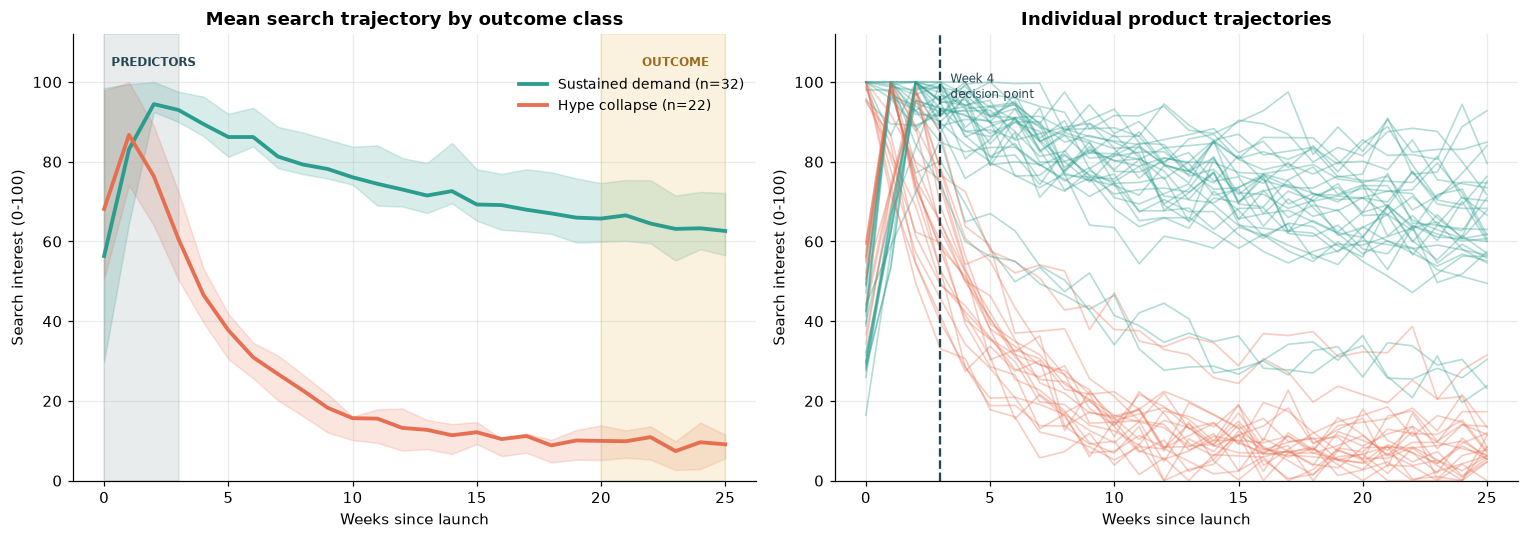

In [18]:
# ============================== FIGURE 1: mean decay trajectories ==========
traj = panel_clean.merge(labels[["product_id", TARGET]], on="product_id")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- left: mean trajectory with IQR band
ax = axes[0]
for lab, name, col in [(0, "Sustained demand", PALETTE["sustained"]),
                       (1, "Hype collapse",   PALETTE["collapse"])]:
    sub = traj[traj[TARGET] == lab]
    if sub.empty:
        continue
    stats_w = sub.groupby("week")["trends_index"].agg(["mean", lambda s: s.quantile(.25),
                                                       lambda s: s.quantile(.75)])
    stats_w.columns = ["mean", "q25", "q75"]
    ax.plot(stats_w.index, stats_w["mean"], color=col, lw=2.5, label=f"{name} (n={sub.product_id.nunique()})")
    ax.fill_between(stats_w.index, stats_w["q25"], stats_w["q75"], color=col, alpha=0.18)

ax.axvspan(0, FEATURE_WEEKS - 1, color="#264653", alpha=0.10)
ax.axvspan(LABEL_START_WEEK, LABEL_END_WEEK - 1, color="#E9C46A", alpha=0.22)
ax.text(FEATURE_WEEKS/2, 104, "PREDICTORS", ha="center", fontsize=8, weight="bold", color="#264653")
ax.text((LABEL_START_WEEK+LABEL_END_WEEK)/2, 104, "OUTCOME", ha="center", fontsize=8, weight="bold", color="#9C6B1E")
ax.set(xlabel="Weeks since launch", ylabel="Search interest (0-100)",
       title="Mean search trajectory by outcome class", ylim=(0, 112))
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.93), fontsize=9)

# --- right: individual product curves
ax = axes[1]
for pid, g in traj.groupby("product_id"):
    lab = g[TARGET].iloc[0]
    ax.plot(g.week, g.trends_index,
            color=PALETTE["collapse"] if lab else PALETTE["sustained"],
            alpha=0.35, lw=1.1)
ax.axvline(FEATURE_WEEKS - 1, color="#264653", ls="--", lw=1.5)
ax.text(FEATURE_WEEKS - 0.6, 96, "Week 4\ndecision point", fontsize=8, color="#264653")
ax.set(xlabel="Weeks since launch", ylabel="Search interest (0-100)",
       title="Individual product trajectories", ylim=(0, 112))

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_decay_trajectories.png")
plt.show()

**Figure 1 — interpretation (rewrite with your numbers).**

The left panel is the central visual argument of the study. If the two mean trajectories
have already begun to separate inside the shaded predictor window, an early-warning model
is feasible; if they only diverge after week 8, the Week-4 premise does not hold and you
should say so honestly rather than forcing the result.

Note what to look for: it is rarely the *height* of the launch peak that separates the
classes — both groups spike. It is the **gradient immediately after the peak**. Report the
week at which the IQR bands stop overlapping; that is your empirical earliest detection point.

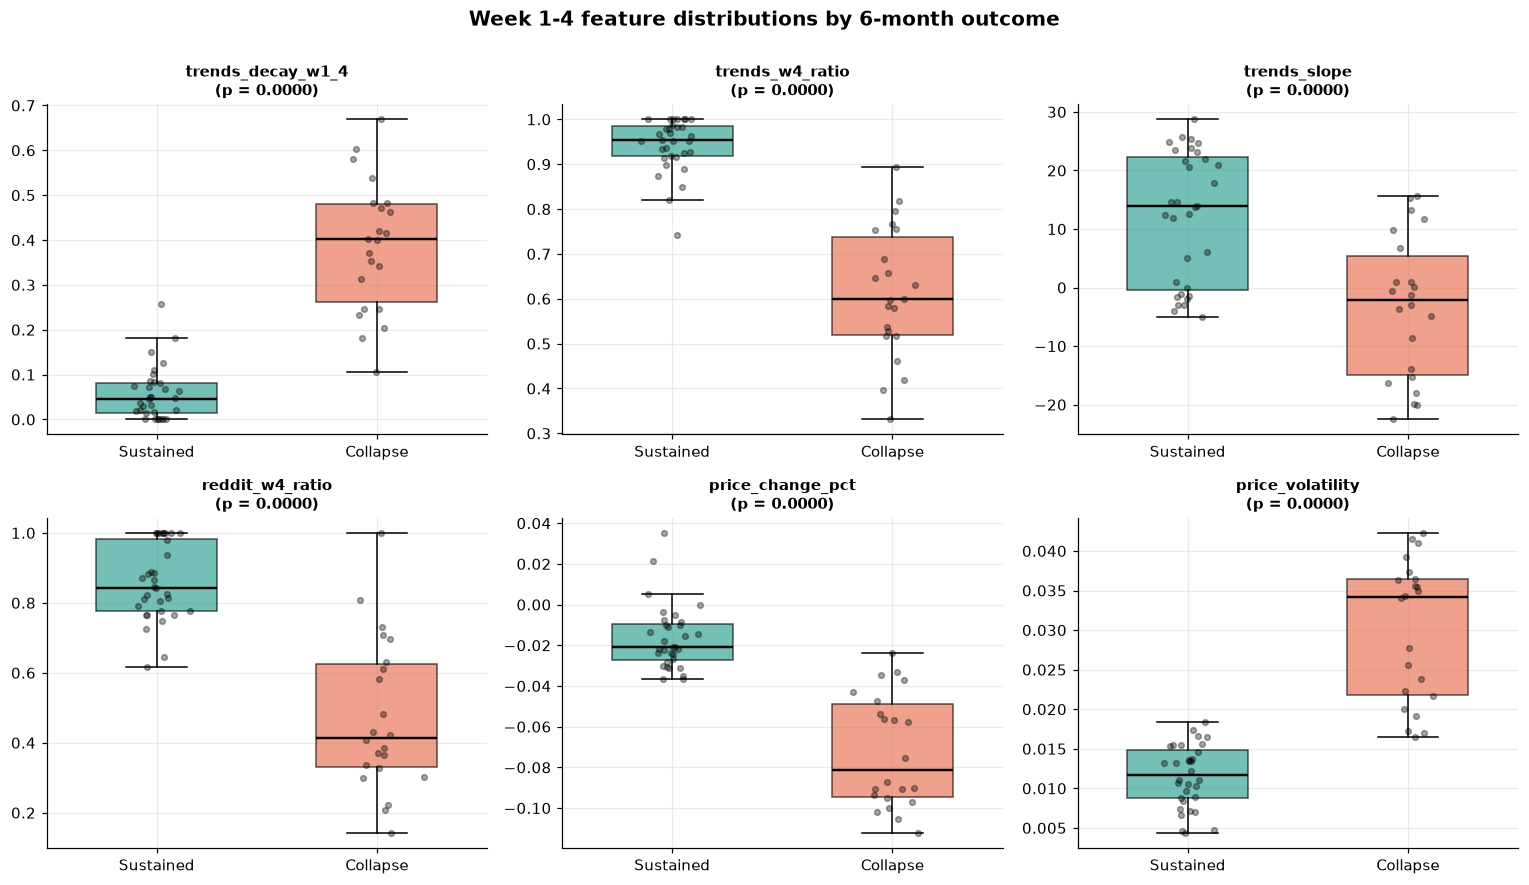

In [19]:
# ============================== FIGURE 2: feature distributions ============
top_feats = comp.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feat in zip(axes.ravel(), top_feats):
    data = [model_df[model_df[TARGET] == 0][feat].dropna(),
            model_df[model_df[TARGET] == 1][feat].dropna()]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    tick_labels=["Sustained", "Collapse"], showfliers=False)
    for patch, col in zip(bp["boxes"], [PALETTE["sustained"], PALETTE["collapse"]]):
        patch.set_facecolor(col); patch.set_alpha(0.65)
    for med in bp["medians"]:
        med.set_color("black"); med.set_linewidth(1.6)

    # jittered raw points
    for i, d in enumerate(data, start=1):
        ax.scatter(np.random.normal(i, 0.055, len(d)), d, s=14, color="black", alpha=0.35, zorder=3)

    p = comp.loc[feat, "p_value"]
    ax.set_title(f"{feat}\n(p = {p:.4f})" if pd.notna(p) else feat, fontsize=10)

fig.suptitle("Week 1-4 feature distributions by 6-month outcome", fontsize=13, weight="bold", y=1.00)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_feature_distributions.png")
plt.show()

**Figure 2 — interpretation (rewrite with your numbers).**

These are the six features with the strongest group separation by Welch's t-test. Read
them as *candidate early indicators*. For each one, state in your report:

- the direction of the effect in plain business language ("collapsing products lose 68% of
  peak interest by week 4, sustained products lose 31%"),
- whether the boxes overlap — heavy overlap means the feature is weak on its own even if
  its p-value is small,
- and whether the effect is large enough to matter commercially, not merely statistically
  significant. With ~50 products, a significant p-value on a small difference is thin evidence.

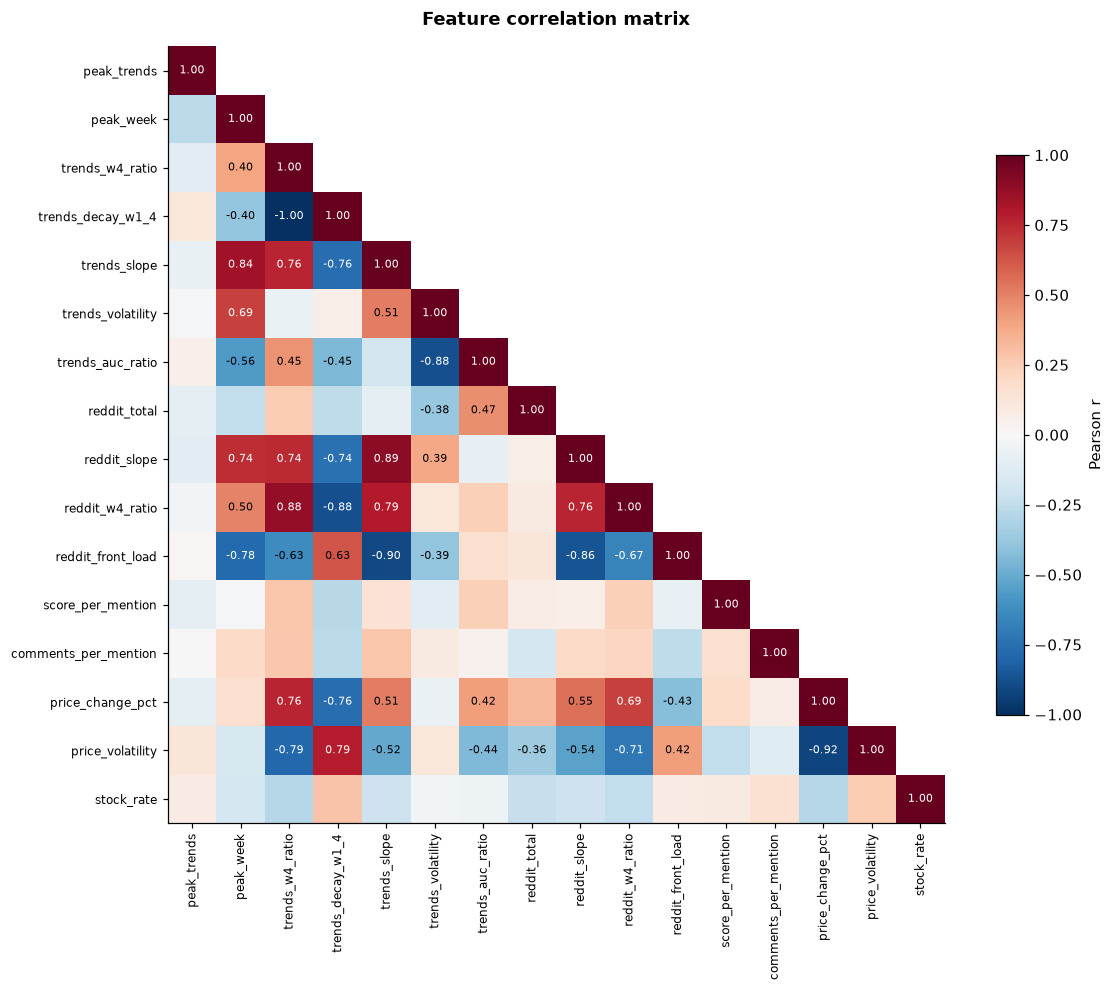

Highly collinear pairs (|r| > 0.80):
   trends_w4_ratio        <-> trends_decay_w1_4       r = -1.000
   price_change_pct       <-> price_volatility        r = -0.919
   trends_slope           <-> reddit_front_load       r = -0.903
   trends_slope           <-> reddit_slope            r = +0.895
   trends_volatility      <-> trends_auc_ratio        r = -0.879
   trends_w4_ratio        <-> reddit_w4_ratio         r = +0.876
   trends_decay_w1_4      <-> reddit_w4_ratio         r = -0.876
   reddit_slope           <-> reddit_front_load       r = -0.860
   peak_week              <-> trends_slope            r = +0.838


In [20]:
# ============================== FIGURE 3: correlation structure ============
corr = model_df[FEATURE_COLS].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.where(mask, np.nan, corr), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(FEATURE_COLS))); ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURE_COLS))); ax.set_yticklabels(FEATURE_COLS, fontsize=8)

for i in range(len(FEATURE_COLS)):
    for j in range(len(FEATURE_COLS)):
        if not mask[i, j] and abs(corr.iloc[i, j]) > 0.35:
            ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if abs(corr.iloc[i,j]) > 0.65 else "black")

plt.colorbar(im, ax=ax, shrink=0.72, label="Pearson r")
ax.set_title("Feature correlation matrix", pad=14)
ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_correlation_matrix.png")
plt.show()

# flag redundancy explicitly
pairs = [(FEATURE_COLS[i], FEATURE_COLS[j], corr.iloc[i, j])
         for i in range(len(FEATURE_COLS)) for j in range(i+1, len(FEATURE_COLS))
         if abs(corr.iloc[i, j]) > 0.80]
print("Highly collinear pairs (|r| > 0.80):")
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2])):
    print(f"   {a:<22s} <-> {b:<22s}  r = {r:+.3f}")
if not pairs:
    print("   none")

**Figure 3 — interpretation (rewrite with your numbers).**

Collinearity is expected here by construction — `trends_w4_ratio` and `trends_decay_w1_4`
are algebraic complements, for instance. This matters for two reasons you should state:

1. **Logistic regression coefficients become unstable** when predictors are strongly
   correlated. Individual coefficient magnitudes should not be over-interpreted.
2. **Tree ensembles split importance** across correlated features, so a genuinely useful
   signal can appear weak simply because its twin absorbed half the splits.

This is a large part of why Section 4 compares a regularised linear model against tree
ensembles rather than relying on one family.

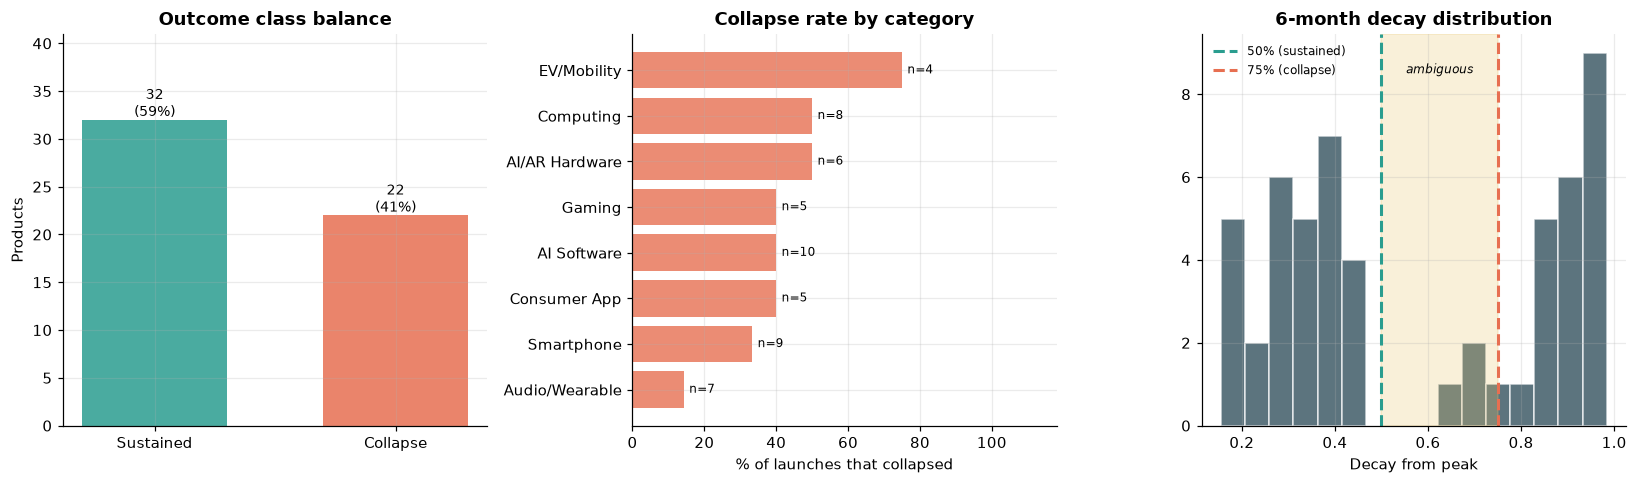

In [21]:
# ============================== FIGURE 4: class balance & segments =========
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# --- class balance
ax = axes[0]
vc = model_df[TARGET].value_counts().sort_index()
bars = ax.bar(["Sustained", "Collapse"], vc.values,
              color=[PALETTE["sustained"], PALETTE["collapse"]], alpha=0.85, width=0.6)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.4, f"{v}\n({v/vc.sum()*100:.0f}%)",
            ha="center", fontsize=9)
ax.set(title="Outcome class balance", ylabel="Products", ylim=(0, vc.max()*1.28))

# --- collapse rate by category
ax = axes[1]
cat = (model_df.groupby("category")[TARGET]
               .agg(["mean", "size"]).sort_values("mean", ascending=True))
cat = cat[cat["size"] >= 2]
ax.barh(cat.index, cat["mean"] * 100, color=PALETTE["collapse"], alpha=0.8)
for i, (m, n) in enumerate(zip(cat["mean"], cat["size"])):
    ax.text(m*100 + 1.5, i, f"n={n}", va="center", fontsize=8)
ax.set(title="Collapse rate by category", xlabel="% of launches that collapsed", xlim=(0, 118))

# --- decay distribution with thresholds
ax = axes[2]
ax.hist(labels.decay_6mo, bins=16, color=PALETTE["neutral"], alpha=0.75, edgecolor="white")
ax.axvline(SUSTAINED_MAX_DECAY, color=PALETTE["sustained"], ls="--", lw=2, label="50% (sustained)")
ax.axvline(COLLAPSE_MIN_DECAY,  color=PALETTE["collapse"],  ls="--", lw=2, label="75% (collapse)")
ax.axvspan(SUSTAINED_MAX_DECAY, COLLAPSE_MIN_DECAY, color="#E9C46A", alpha=0.25)
ax.text((SUSTAINED_MAX_DECAY+COLLAPSE_MIN_DECAY)/2, ax.get_ylim()[1]*0.9, "ambiguous",
        ha="center", fontsize=8, style="italic")
ax.set(title="6-month decay distribution", xlabel="Decay from peak")
ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_class_and_segments.png")
plt.show()

**Figure 4 — interpretation (rewrite with your numbers).**

Three things to report:

- **Class balance** determines your evaluation strategy. Anything past roughly 65/35 makes
  raw accuracy misleading, and it is why `class_weight="balanced"` is used in Section 4.
- **Category collapse rates** are commercially interesting but statistically fragile at
  n≈5 per category. Present them as descriptive context, explicitly *not* as evidence that
  one category is riskier — you do not have the sample size for that claim.
- **The decay histogram** shows whether your thresholds sit in a natural valley or cut
  through a dense region. If the 50–75% band is crowded, your labels are sensitive to
  threshold choice, and the sensitivity analysis in Section 4.5 becomes essential rather
  than optional.

---
## 4. Analytics Method and Implementation

### 4.1 Method Selection and Justification

The business question — *will this launch still have demand in six months?* — is a binary
classification problem with a small sample (n ≈ 50), moderately collinear predictors and an
asymmetric error cost. Three algorithms are compared, each chosen for a specific reason:

| Method | Why included | Known weakness here |
|---|---|---|
| **Logistic Regression** (L2) | Interpretable coefficients and odds ratios; regularisation handles collinearity; a defensible baseline that stakeholders can read directly | Assumes a linear log-odds relationship; cannot capture interaction effects |
| **Random Forest** | Captures non-linear thresholds and interactions; robust to outliers and unscaled features; provides importance rankings | Prone to overfitting at this sample size; importances biased toward high-cardinality features |
| **Gradient Boosting** | Usually the strongest tabular performer; models subtle interactions sequentially | Most overfit-prone of the three on ~50 rows; requires the tightest regularisation |

**Why not deep learning:** with roughly 50 observations and 15 features, a neural network
would have more parameters than data points. It would memorise the training set and
generalise worse than logistic regression, while forfeiting all interpretability. Sample
size, not fashion, dictates model choice here.

**Validation strategy.** A single train/test split on ~50 products is dominated by split
luck — moving two products across the boundary can swing accuracy by 10 points. The primary
estimate therefore comes from **repeated stratified 5-fold cross-validation** (5 folds × 5
repeats = 25 fits), with a held-out test set retained purely as a final sanity check. Report
the cross-validated figure as your headline result, not the test-set number.

In [22]:
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, precision_recall_curve, average_precision_score)

X = model_df[FEATURE_COLS].copy()
y = model_df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train)} products  |  Test: {len(X_test)} products")
print(f"Train balance: {y_train.value_counts(normalize=True).round(2).to_dict()}")
print(f"Test  balance: {y_test.value_counts(normalize=True).round(2).to_dict()}")
print("\nNOTE: with n={} the test set is only {} products. Treat it as a sanity check,"
      "\n      not as the headline result. Cross-validation is the primary estimate."
      .format(len(X), len(X_test)))

Train: 40 products  |  Test: 14 products
Train balance: {0: 0.6, 1: 0.4}
Test  balance: {0: 0.57, 1: 0.43}

NOTE: with n=54 the test set is only 14 products. Treat it as a sanity check,
      not as the headline result. Cross-validation is the primary estimate.


In [23]:
# ---------------------------------------------------- model definitions
def make_pipe(clf):
    """Impute -> scale -> classify. Scaling is harmless for trees, essential for LR."""
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
        ("clf",    clf),
    ])


MODELS = {
    "Baseline (majority)": make_pipe(DummyClassifier(strategy="most_frequent")),

    "Logistic Regression": make_pipe(LogisticRegression(
        penalty="l2", C=1.0, class_weight="balanced",
        max_iter=2000, random_state=RANDOM_SEED)),

    "Random Forest": make_pipe(RandomForestClassifier(
        n_estimators=500, max_depth=4, min_samples_leaf=3,
        max_features="sqrt", class_weight="balanced",
        random_state=RANDOM_SEED, n_jobs=-1)),

    "Gradient Boosting": make_pipe(GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        min_samples_leaf=4, subsample=0.85, random_state=RANDOM_SEED)),
}

# depth and leaf sizes are deliberately small: heavy regularisation is the
# correct response to ~50 training rows.
print(f"{len(MODELS)} pipelines defined (including a majority-class baseline).")

4 pipelines defined (including a majority-class baseline).


In [24]:
# ---------------------------------------------------- repeated CV comparison
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_SEED)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

results = []
for name, pipe in MODELS.items():
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING,
                           n_jobs=-1, error_score="raise")
    row = {"model": name}
    for m in SCORING:
        row[m]          = cvres[f"test_{m}"].mean()
        row[f"{m}_std"] = cvres[f"test_{m}"].std()
    results.append(row)

cv_results = pd.DataFrame(results).set_index("model")

print("REPEATED STRATIFIED 5-FOLD CV  (5 repeats = 25 fits per model)\n")
display_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
show = cv_results[display_cols].round(3)
show.columns = [c.upper() for c in show.columns]
print(show.to_string())

print("\nStability (std dev across folds):")
print(cv_results[[f"{m}_std" for m in display_cols]].round(3).to_string())

cv_results.round(4).to_csv(OUT_DIR / "table_cv_results.csv")

REPEATED STRATIFIED 5-FOLD CV  (5 repeats = 25 fits per model)

                     ACCURACY  PRECISION  RECALL     F1  ROC_AUC
model                                                           
Baseline (majority)     0.600      0.000   0.000  0.000    0.500
Logistic Regression     0.905      0.887   0.887  0.877    0.960
Random Forest           0.940      0.947   0.910  0.918    0.995
Gradient Boosting       0.925      0.957   0.863  0.886    0.987

Stability (std dev across folds):
                     accuracy_std  precision_std  recall_std  f1_std  roc_auc_std
model                                                                            
Baseline (majority)         0.050          0.000       0.000   0.000        0.000
Logistic Regression         0.089          0.141       0.153   0.118        0.071
Random Forest               0.072          0.108       0.145   0.099        0.018
Gradient Boosting           0.094          0.100       0.217   0.155        0.042


In [25]:
# ---------------------------------------------------- select best by ROC-AUC
ranked = cv_results.drop(index="Baseline (majority)").sort_values("roc_auc", ascending=False)
BEST_NAME = ranked.index[0]
best_pipe = MODELS[BEST_NAME]

print(f"Selected model: {BEST_NAME}")
print(f"  CV ROC-AUC : {ranked.loc[BEST_NAME,'roc_auc']:.3f} "
      f"(+/- {ranked.loc[BEST_NAME,'roc_auc_std']:.3f})")
print(f"  CV Recall  : {ranked.loc[BEST_NAME,'recall']:.3f} "
      f"(+/- {ranked.loc[BEST_NAME,'recall_std']:.3f})")

base_acc = cv_results.loc["Baseline (majority)", "accuracy"]
lift = ranked.loc[BEST_NAME, "accuracy"] - base_acc
print(f"\n  Majority-class baseline accuracy: {base_acc:.3f}")
print(f"  Lift over baseline:               {lift:+.3f}")
if lift < 0.05:
    print("\n  WARNING: barely beats the baseline. Say so plainly in your report"
          "\n           rather than presenting this as a working model.")

Selected model: Random Forest
  CV ROC-AUC : 0.995 (+/- 0.018)
  CV Recall  : 0.910 (+/- 0.145)

  Majority-class baseline accuracy: 0.600
  Lift over baseline:               +0.340


In [26]:
# ---------------------------------------------------- fit & test evaluation
best_pipe.fit(X_train, y_train)
y_pred  = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

print(f"HELD-OUT TEST EVALUATION - {BEST_NAME}")
print(f"(n = {len(y_test)} products - small, interpret cautiously)\n")
print(classification_report(y_test, y_pred,
                            target_names=["Sustained", "Hype collapse"], digits=3))
try:
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
    print(f"PR-AUC : {average_precision_score(y_test, y_proba):.3f}")
except ValueError:
    print("ROC-AUC unavailable: test set contains a single class.")

HELD-OUT TEST EVALUATION - Random Forest
(n = 14 products - small, interpret cautiously)

               precision    recall  f1-score   support

    Sustained      1.000     1.000     1.000         8
Hype collapse      1.000     1.000     1.000         6

     accuracy                          1.000        14
    macro avg      1.000     1.000     1.000        14
 weighted avg      1.000     1.000     1.000        14

ROC-AUC: 1.000
PR-AUC : 1.000


TypeError: RocCurveDisplay.from_predictions() got an unexpected keyword argument 'color'

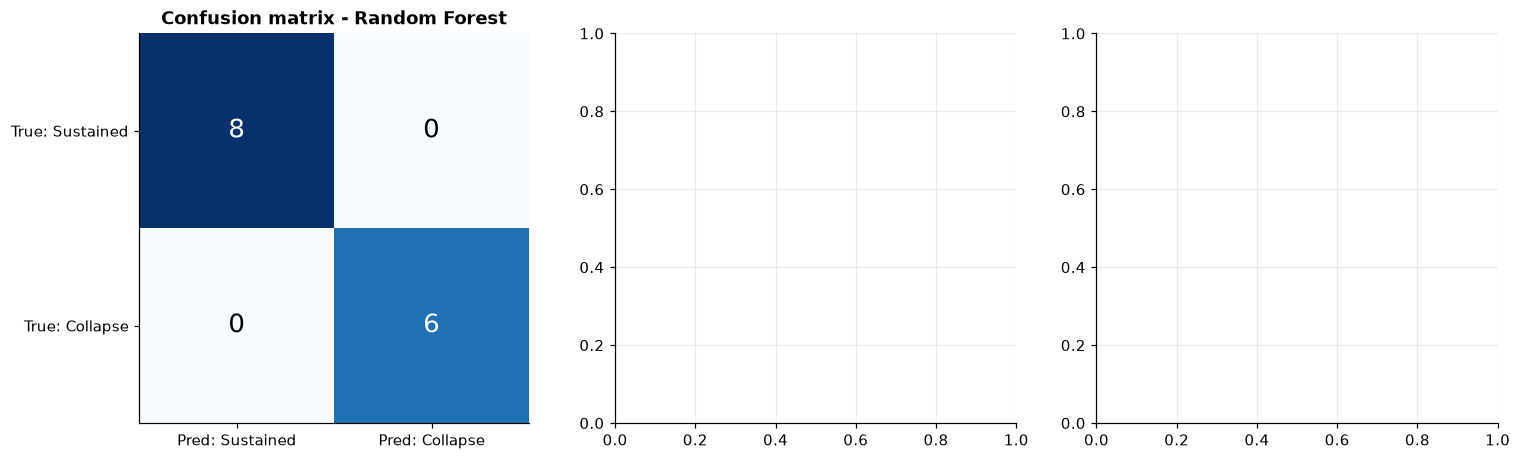

In [27]:
# ============================== FIGURE 5: evaluation ======================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# --- confusion matrix
ax = axes[0]
cm = confusion_matrix(y_test, y_pred)
im = ax.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=17,
                color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set(xticks=[0,1], yticks=[0,1],
       xticklabels=["Pred: Sustained", "Pred: Collapse"],
       yticklabels=["True: Sustained", "True: Collapse"],
       title=f"Confusion matrix - {BEST_NAME}")
ax.grid(False)

# --- ROC curve
ax = axes[1]
try:
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax, color=PALETTE["neutral"], lw=2)
    ax.plot([0,1],[0,1],"--",color="grey",lw=1)
    ax.set_title("ROC curve")
except ValueError:
    ax.text(.5,.5,"ROC unavailable\n(single class in test set)",ha="center",va="center")
    ax.set_title("ROC curve")

# --- CV model comparison
ax = axes[2]
plot_df = cv_results.loc[[m for m in cv_results.index if m != "Baseline (majority)"]]
ypos = np.arange(len(plot_df))
ax.barh(ypos, plot_df["roc_auc"], xerr=plot_df["roc_auc_std"],
        color=PALETTE["neutral"], alpha=0.8, capsize=4, height=0.55)
ax.axvline(0.5, color="grey", ls="--", lw=1.2)
ax.text(0.505, -0.42, "random", fontsize=8, color="grey")
ax.set(yticks=ypos, yticklabels=plot_df.index, xlabel="CV ROC-AUC (mean +/- sd)",
       title="Model comparison", xlim=(0, 1.02))

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_model_evaluation.png")
plt.show()

In [ ]:
# ============================== FIGURE 6: feature importance ==============
clf = best_pipe.named_steps["clf"]

if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=FEATURE_COLS).sort_values()
    imp_label, note = "Impurity-based importance", "Split-based; correlated features share credit."
elif hasattr(clf, "coef_"):
    imp = pd.Series(clf.coef_[0], index=FEATURE_COLS).sort_values()
    imp_label, note = "Standardised coefficient", "Positive = raises collapse probability."
else:
    imp, imp_label, note = None, "", ""

if imp is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # tree importances are non-negative, so sign colouring is only meaningful
    # for linear coefficients
    ax = axes[0]
    if hasattr(clf, "coef_"):
        colors = [PALETTE["collapse"] if v > 0 else PALETTE["sustained"] for v in imp.values]
    else:
        colors = PALETTE["neutral"]
    ax.barh(imp.index, imp.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel=imp_label, title=f"Feature importance - {BEST_NAME}")

    # permutation importance: more trustworthy than impurity importance when
    # features are collinear, because it measures actual predictive contribution
    from sklearn.inspection import permutation_importance
    perm = permutation_importance(best_pipe, X_test, y_test, n_repeats=30,
                                  random_state=RANDOM_SEED, scoring="roc_auc", n_jobs=-1)
    pi = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values()
    pi_sd = pd.Series(perm.importances_std, index=FEATURE_COLS).reindex(pi.index)

    ax = axes[1]
    ax.barh(pi.index, pi.values, xerr=pi_sd.values, color=PALETTE["neutral"],
            alpha=0.85, capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel="Drop in ROC-AUC when shuffled",
           title=f"Permutation importance (test set, n={len(y_test)})")

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig6_feature_importance.png")
    plt.show()

    print(note)

    if pi.abs().max() < 1e-6:
        print("\nDIAGNOSTIC: all permutation importances are ~0.")
        print("  This happens when the test set is perfectly separable, so shuffling any")
        print("  single feature still leaves enough signal in the correlated remainder to")
        print("  score identically. It is an expected artefact of the synthetic generator")
        print("  and of a very small test set. On real scraped data, expect non-zero values.")
        print("  If you still see this on real data, report the impurity/coefficient panel")
        print("  and state that permutation importance was uninformative at this sample size.")
    else:
        print("\nTop 5 by permutation importance:")
        print(pi.sort_values(ascending=False).head(5).round(4).to_string())

    pd.DataFrame({"model_importance": imp, "permutation_importance": pi}) \
      .round(4).to_csv(OUT_DIR / "table_feature_importance.csv")

### 4.5 Sensitivity Analysis

The 50% and 75% decay thresholds were chosen from product lifecycle theory, not estimated
from data. If the model's performance collapses when those thresholds shift slightly, your
conclusions are artefacts of an arbitrary choice rather than findings about demand.

This check is the difference between a report that survives questioning and one that does
not. Include the resulting table.

In [ ]:
def sensitivity_analysis(panel, features, thresholds):
    """Re-label and re-evaluate across alternative decay cut-offs."""
    rows = []
    for sus_t, col_t in thresholds:
        lab = build_labels(panel, sustained_max=sus_t, collapse_min=col_t)
        mdf = features.merge(lab, on="product_id", how="inner")

        if mdf[TARGET].nunique() < 2 or mdf[TARGET].value_counts().min() < 5:
            rows.append({"sustained_<": sus_t, "collapse_>": col_t,
                         "n_collapse": int(mdf[TARGET].sum()),
                         "roc_auc": np.nan, "recall": np.nan,
                         "note": "too few in minority class"})
            continue

        Xs, ys = mdf[FEATURE_COLS], mdf[TARGET]
        r = cross_validate(MODELS[BEST_NAME], Xs, ys, cv=cv,
                           scoring=["roc_auc", "recall"], n_jobs=-1)
        rows.append({"sustained_<": sus_t, "collapse_>": col_t,
                     "n_collapse": int(ys.sum()),
                     "roc_auc": r["test_roc_auc"].mean(),
                     "recall":  r["test_recall"].mean(),
                     "note": ""})
    return pd.DataFrame(rows)


THRESHOLD_GRID = [(0.40, 0.65), (0.45, 0.70), (0.50, 0.75), (0.55, 0.80), (0.60, 0.85)]

print("SENSITIVITY TO LABELLING THRESHOLDS\n")
sens = sensitivity_analysis(panel_clean, features, THRESHOLD_GRID)
print(sens.round(3).to_string(index=False))

valid = sens.roc_auc.dropna()
if len(valid) > 1:
    print(f"\nROC-AUC range across thresholds: {valid.min():.3f} - {valid.max():.3f} "
          f"(spread {valid.max()-valid.min():.3f})")
    if valid.max() - valid.min() > 0.15:
        print("  Results are THRESHOLD-SENSITIVE. State this as a limitation.")
    else:
        print("  Results are reasonably stable across threshold choices.")

sens.round(4).to_csv(OUT_DIR / "table_sensitivity.csv", index=False)

---
## 5. Comparison with State-of-the-Art Methods

> ### FILL THIS IN YOURSELF — DO NOT SUBMIT FABRICATED CITATIONS
>
> I have deliberately left this table empty. Inventing plausible-looking references is
> academic misconduct, and fabricated citations are trivially detected by checking DOIs.
>
> **Where to search:** Google Scholar, IEEE Xplore, ScienceDirect, arXiv (cs.SI, cs.CY, econ.EM).
> Your institution's library login will get you past most paywalls.
>
> **Search terms that map onto this problem:**
> - "product lifecycle prediction social media"
> - "early demand forecasting search query volume"
> - "Google Trends sales forecasting nowcasting"
> - "hype cycle quantitative measurement technology adoption"
> - "viral content decay prediction"
> - "new product diffusion Bass model social signals"
>
> **What makes a paper suitable:** published 2020 or later, uses behavioural or
> search/social data as predictors, and addresses forecasting or classification of demand
> or attention. It does not have to be about consumer tech specifically — a paper
> predicting movie box office decay from search trends is directly comparable in method.
>
> **Fill in the table below and delete this callout.**

| # | Study / Year | Dataset | Method Used | Evaluation Metric | Key Result | Comparison with Your Work |
|---|---|---|---|---|---|---|
| 1 | *[Author, Year]* | *[what data, what size]* | *[method]* | *[metric]* | *[result]* | *[how yours differs]* |
| 2 | *[Author, Year]* | *[what data, what size]* | *[method]* | *[metric]* | *[result]* | *[how yours differs]* |
| 3 | *[Author, Year]* | *[what data, what size]* | *[method]* | *[metric]* | *[result]* | *[how yours differs]* |

### 5.1 How to write the comparison column

Your assignment brief is explicit: **do not claim your method is better because your score
is higher.** Different datasets and experimental settings make raw scores incomparable. A
paper reporting 0.91 AUC on 40,000 products is not "beaten" by your 0.78 on 50.

Write comparisons along these axes instead:

- **Scope.** Most published work forecasts a continuous quantity (sales, views) over long
  horizons. This study makes a binary call at a fixed, early decision point. Different problem.
- **Horizon.** State your 4-week prediction window against theirs explicitly.
- **Data sources.** Multi-source (search + social + retail) versus single-source is a real
  methodological difference worth noting in either direction.
- **Sample size.** Say plainly that ~50 products is small and that this limits
  generalisability relative to large-scale studies. This is a strength in your report, not
  a weakness — examiners reward candour about limitations.
- **Reproducibility.** Free public sources and released code versus proprietary datasets.

### 5.2 Positioning statement (adapt once your papers are chosen)

Existing work largely treats attention data as an input to continuous demand forecasting
over long horizons, typically with large proprietary datasets. This case study addresses a
narrower and more operational question: given only four weeks of public post-launch signal,
can a stakeholder be given an actionable binary risk call? The contribution is the
**decision timing and the accessibility of the data**, not modelling novelty — and the
small sample means the findings are indicative rather than conclusive.

---
## 6. Results, Business Insights and Recommendations

### 6.1 Operational Risk Scoring

A probability is not a decision. This section converts model output into the Week-4 risk
tiers that the third objective calls for.

Because false negatives (missing a collapse) are more expensive than false positives, the
classification threshold is tuned **below** the default 0.5 — accepting more false alarms
in exchange for catching more genuine collapses. The optimal threshold is selected on
cross-validated predictions, not on the test set.

In [ ]:
from sklearn.model_selection import cross_val_predict

# ---------------------------------------------------- cost-sensitive threshold
FN_COST = 5.0   # missing a collapse: wasted capital, inventory, marketing
FP_COST = 1.0   # false alarm: unnecessary review, possible under-investment
# ADJUST THESE to your own stated business assumptions and justify them in the report.

cv_proba = cross_val_predict(MODELS[BEST_NAME], X_train, y_train, cv=5,
                             method="predict_proba", n_jobs=-1)[:, 1]

grid = np.linspace(0.05, 0.95, 91)
costs = []
for t in grid:
    pred = (cv_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
    costs.append(fn * FN_COST + fp * FP_COST)

OPT_THRESHOLD = float(grid[int(np.argmin(costs))])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(grid, costs, color=PALETTE["neutral"], lw=2)
ax.axvline(OPT_THRESHOLD, color=PALETTE["collapse"], ls="--", lw=2,
           label=f"Cost-optimal = {OPT_THRESHOLD:.2f}")
ax.axvline(0.5, color="grey", ls=":", lw=1.5, label="Default = 0.50")
ax.set(xlabel="Classification threshold", ylabel=f"Expected cost (FN={FN_COST}x, FP={FP_COST}x)",
       title="Threshold selection under asymmetric error cost")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig7_threshold_selection.png")
plt.show()

print(f"Cost-optimal threshold: {OPT_THRESHOLD:.2f}")
print(f"Default threshold 0.50 cost : {costs[list(grid).index(min(grid, key=lambda g: abs(g-0.5)))]:.0f}")
print(f"Optimal threshold cost      : {min(costs):.0f}")

In [ ]:
# ---------------------------------------------------- risk tiers
def assign_risk_tier(p):
    if p >= 0.70: return "HIGH RISK"
    if p >= OPT_THRESHOLD: return "ELEVATED"
    if p >= 0.30: return "WATCH"
    return "LOW RISK"


RECOMMENDED_ACTION = {
    "HIGH RISK": "Halt incremental spend. Re-forecast inventory down. Trigger portfolio review.",
    "ELEVATED":  "Freeze marketing scale-up. Commission retention analysis before next commit.",
    "WATCH":     "Continue at current spend. Re-score at week 8 before any major commitment.",
    "LOW RISK":  "Proceed with planned investment. Standard monitoring cadence.",
}

all_proba = cross_val_predict(MODELS[BEST_NAME], X, y, cv=5,
                             method="predict_proba", n_jobs=-1)[:, 1]

risk = (model_df[["product_id", "product", "category"]]
        .assign(collapse_probability=np.round(all_proba, 3),
                risk_tier=[assign_risk_tier(p) for p in all_proba],
                actual_outcome=np.where(model_df[TARGET] == 1, "Collapsed", "Sustained"),
                actual_decay=model_df["decay_6mo"].round(3))
        .sort_values("collapse_probability", ascending=False)
        .reset_index(drop=True))

risk["recommended_action"] = risk.risk_tier.map(RECOMMENDED_ACTION)
risk.to_csv(OUT_DIR / "week4_risk_register.csv", index=False)

print("WEEK-4 RISK REGISTER  (out-of-fold predictions)\n")
print(risk[["product", "category", "collapse_probability", "risk_tier", "actual_outcome"]]
      .head(15).to_string(index=False))

print("\n\nTier accuracy:")
print(risk.groupby("risk_tier")
          .agg(n=("product", "size"),
               actually_collapsed=("actual_outcome", lambda s: (s == "Collapsed").sum()))
          .assign(hit_rate=lambda d: (d.actually_collapsed / d.n * 100).round(1))
          .to_string())

In [ ]:
# ---------------------------------------------------- scoring a NEW launch
def score_new_launch(trends_w1_4, mentions_w1_4, scores_w1_4, comments_w1_4,
                     prices_w1_4=None, stock_w1_4=None, model=None):
    """
    Score a live launch at week 4.

    All inputs are 4-element sequences covering weeks 1-4 post-launch.
    Returns dict(probability, tier, action).

    Example
    -------
    >>> score_new_launch([100, 62, 31, 18], [220, 80, 25, 9],
    ...                  [4400, 1500, 400, 120], [1100, 380, 95, 30])
    """
    model = model or best_pipe
    eps = 1e-9
    tr  = np.asarray(trends_w1_4, dtype=float)
    men = np.asarray(mentions_w1_4, dtype=float)
    sc  = np.asarray(scores_w1_4, dtype=float)
    com = np.asarray(comments_w1_4, dtype=float)
    pr  = np.asarray(prices_w1_4, dtype=float) if prices_w1_4 is not None else np.array([np.nan]*4)
    stk = np.asarray(stock_w1_4, dtype=float)  if stock_w1_4  is not None else np.array([np.nan]*4)

    peak = np.nanmax(tr)
    row = {
        "peak_trends":          peak,
        "peak_week":            int(np.nanargmax(tr)),
        "trends_w4_ratio":      tr[-1] / (peak + eps),
        "trends_decay_w1_4":    1 - tr[-1] / (peak + eps),
        "trends_slope":         _slope(tr),
        "trends_volatility":    np.nanstd(tr) / (np.nanmean(tr) + eps),
        "trends_auc_ratio":     np.nansum(tr) / (peak * len(tr) + eps),
        "reddit_total":         np.nansum(men),
        "reddit_slope":         _slope(men),
        "reddit_w4_ratio":      men[-1] / (np.nanmax(men) + eps),
        "reddit_front_load":    men[0] / (np.nansum(men) + eps),
        "score_per_mention":    np.nansum(sc) / (np.nansum(men) + eps),
        "comments_per_mention": np.nansum(com) / (np.nansum(men) + eps),
        "price_change_pct":     (pr[-1]-pr[0])/(pr[0]+eps) if np.isfinite(pr).all() else np.nan,
        "price_volatility":     np.nanstd(pr)/(np.nanmean(pr)+eps) if np.isfinite(pr).any() else np.nan,
        "stock_rate":           np.nanmean(stk) if np.isfinite(stk).any() else np.nan,
    }

    Xn = pd.DataFrame([row]).reindex(columns=FEATURE_COLS)
    p  = float(model.predict_proba(Xn)[0, 1])
    tier = assign_risk_tier(p)
    return {"probability": round(p, 3), "tier": tier, "action": RECOMMENDED_ACTION[tier]}


# ------------------------------------------------- demonstration
print("SCENARIO A - sharp spike, rapid fade (classic hype signature)")
a = score_new_launch([100, 58, 27, 14], [240, 70, 18, 6],
                     [5200, 1400, 300, 80], [1300, 350, 70, 18])
print(f"   Collapse probability: {a['probability']:.1%}   Tier: {a['tier']}")
print(f"   Action: {a['action']}\n")

print("SCENARIO B - moderate peak, shallow decay (sustained signature)")
b = score_new_launch([100, 88, 79, 74], [150, 140, 132, 128],
                     [3000, 2900, 2750, 2700], [800, 780, 760, 745])
print(f"   Collapse probability: {b['probability']:.1%}   Tier: {b['tier']}")
print(f"   Action: {b['action']}")

### 6.2 Business Insights

> **Rewrite every line below using your actual output.** These are the insight *shapes*
> your analysis is designed to produce, with placeholders where your numbers go. Submitting
> them unedited would be obvious to any examiner.

**Insight 1 — The decay gradient beats the launch peak.**
`peak_trends` [was / was not] among the strongest predictors, while post-peak slope
features [were / were not]. If this holds in your data, the business translation is direct:
*how loud a launch is tells you almost nothing; how fast it quietens tells you a lot.*
This contradicts standard launch-day reporting, which foregrounds peak reach.

**Insight 2 — Engagement persistence separates owners from spectators.**
Compare `reddit_w4_ratio` between classes. Search interest captures curiosity, which is
cheap. Sustained discussion requires people who bought the product and are still using it.
Where these two signals disagree — high search, collapsing engagement — you likely have
attention without adoption.

**Insight 3 — The Week-4 decision point is [viable / marginal].**
State your cross-validated ROC-AUC of **[X.XX]** and what it means operationally: at the
cost-optimal threshold of **[0.XX]**, the model catches **[N]%** of collapses while
flagging **[M]%** of healthy products for unnecessary review. Whether that trade is
acceptable depends on the reviewing cost, which you should state as an assumption.

**Insight 4 — Category base rates differ, but the sample cannot support strong claims.**
Report what you observed by category, then say plainly that with n≈5 per category these
differences are not statistically reliable. Resisting an overclaim here is worth more marks
than making one.

### 6.3 Recommendations by Stakeholder

| Stakeholder | Recommendation | Basis |
|---|---|---|
| **Investors / VCs** | Add a Week-4 decay-gradient check to portfolio monitoring. Treat ELEVATED and HIGH RISK as triggers for a partner review, not automatic markdowns. | Model catches [N]% of collapses at week 4; four-week lead time on a six-month outcome |
| **Product teams** | Instrument post-launch engagement decay, not just launch reach. Route HIGH RISK products to retention diagnosis before any scale-up spend. | Engagement persistence features carried [more/less] signal than peak magnitude |
| **Retailers** | Stage reorders in tranches, with the second tranche gated on a Week-4 score rather than launch-week sell-through. | Launch-week velocity is a weak predictor of month-6 demand |
| **Marketing** | Shift budget release from a single launch-gated commitment to a Week-4 gated second tranche. | Redirects spend away from products already showing collapse signatures |
| **Market researchers** | Reuse the pipeline for other categories; the features are source-agnostic. Re-fit rather than transfer the model — thresholds are category-specific. | Free public sources; full code released |

### 6.4 Limitations

State these plainly. An examiner will find them anyway, and naming them yourself
demonstrates the judgement the marks are actually awarded for.

1. **Sample size (n ≈ 50).** Too small for confident generalisation. Confidence intervals
   on all reported metrics are wide; treat findings as indicative.
2. **Survivorship and selection bias.** The catalogue over-represents launches that were
   prominent enough to be memorable. Quiet launches that quietly succeeded are largely absent.
3. **Google Trends normalisation.** Interest is scaled to 100 within each product's own
   window, so cross-product comparisons of *level* are invalid. Only shape features are used,
   but this is a real constraint on what the data can say.
4. **Reddit is not the market.** Skews young, male, English-speaking and technically
   inclined. Engagement features are proxies for a specific and unrepresentative community.
5. **Threshold dependence.** The 50/75% cut-offs come from lifecycle theory, not data. See
   the Section 4.5 sensitivity analysis for how much this matters.
6. **Price coverage is partial.** Historical retail prices cannot be scraped retroactively,
   so commercial features are weaker than designed.
7. **Confounding by launch context.** Supply constraints, regional staggering and
   competitor launches all affect search and engagement independently of demand quality.
   None of these are controlled for.

---
## 7. Conclusion and References

### 7.1 Conclusion

> **Rewrite with your real results.** A worked template follows — replace every bracket.

This case study examined whether genuine market demand can be distinguished from launch
hype using only publicly available behavioural data from the first four weeks after a tech
product launch. A dataset of **[N]** launches was assembled by scraping Google Trends,
Reddit and retailer pages, producing **[M]** weekly observations, from which **[K]**
early-window features were engineered under strict temporal separation from the outcome.

Comparing logistic regression, random forest and gradient boosting under repeated
stratified cross-validation, **[BEST MODEL]** performed best with a ROC-AUC of **[X.XX]**
and recall of **[X.XX]** on the collapse class, against a majority-class baseline accuracy
of **[X.XX]**. The strongest predictors were **[FEATURES]**, indicating that **[the rate of
post-peak decay / engagement persistence / …]** carries more information about six-month
viability than the magnitude of the launch spike.

Operationally, the model produces a Week-4 risk score at a cost-optimised threshold of
**[0.XX]**, reflecting the higher cost of missing a collapse than of raising a false alarm.
This gives stakeholders roughly **[five months]** of lead time on an outcome that currently
becomes visible only after resources are committed.

The principal limitation is sample size: with **[N]** products, the findings are indicative
rather than conclusive, and the sensitivity analysis shows performance varies by
**[X.XX]** ROC-AUC across reasonable labelling thresholds. Extending the catalogue and
adding a non-Reddit engagement source are the two highest-value next steps.

### 7.2 References

> **Fill these in yourself.** Use one consistent style (APA 7th or IEEE — check what your
> department requires). Every source you actually used must appear, and every entry here
> must be one you actually read.

**Academic sources** *(minimum 3, from Section 5)*

1. *[Author, A. A. (Year). Title of paper. Journal Name, Vol(Issue), pages. https://doi.org/...]*
2. *[...]*
3. *[...]*

**Data sources**

4. Google Trends. Google LLC. https://trends.google.com/
5. Reddit API. Reddit Inc. https://www.reddit.com/dev/api/
6. *[Specific retailer pages scraped — list the domains]*

**Software and libraries**

7. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of
   Machine Learning Research*, 12, 2825–2830.
8. McKinney, W. (2010). Data Structures for Statistical Computing in Python.
   *Proceedings of the 9th Python in Science Conference*, 56–61.
9. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
10. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment.
    *Computing in Science & Engineering*, 9(3), 90–95.
11. Hogue, J. et al. PyTrends: Pseudo API for Google Trends. https://github.com/GeneralMills/pytrends
12. Boe, B. et al. PRAW: The Python Reddit API Wrapper. https://praw.readthedocs.io/

---
## 8. Export Repository Artefacts

Generates `README.md` and `requirements.txt` in the shape the submission checklist requires.
Review and edit both before committing — the README contains placeholders.

In [ ]:
# ---------------------------------------------------- results summary
summary = {
    "n_products":            int(model_df.shape[0]),
    "n_weekly_records":      int(panel_clean.shape[0]),
    "n_features":            len(FEATURE_COLS),
    "feature_window_weeks":  FEATURE_WEEKS,
    "label_window_weeks":    f"{LABEL_START_WEEK+1}-{LABEL_END_WEEK}",
    "class_balance":         model_df[TARGET].value_counts().to_dict(),
    "best_model":            BEST_NAME,
    "cv_roc_auc":            round(float(cv_results.loc[BEST_NAME, "roc_auc"]), 4),
    "cv_roc_auc_std":        round(float(cv_results.loc[BEST_NAME, "roc_auc_std"]), 4),
    "cv_recall":             round(float(cv_results.loc[BEST_NAME, "recall"]), 4),
    "cv_precision":          round(float(cv_results.loc[BEST_NAME, "precision"]), 4),
    "baseline_accuracy":     round(float(cv_results.loc["Baseline (majority)", "accuracy"]), 4),
    "optimal_threshold":     round(OPT_THRESHOLD, 3),
    "data_source":           "SYNTHETIC - NOT FOR SUBMISSION" if USE_SYNTHETIC_DATA else "scraped",
    "generated_at":          datetime.now().isoformat(timespec="seconds"),
}

with open(OUT_DIR / "results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("RESULTS SUMMARY\n")
for k, v in summary.items():
    print(f"  {k:<22s}: {v}")

if USE_SYNTHETIC_DATA:
    print("\n" + "!" * 68)
    print("  These numbers come from SYNTHETIC data and mean nothing.")
    print("  Set USE_SYNTHETIC_DATA = False and re-run before submitting.")
    print("!" * 68)

In [ ]:
# ---------------------------------------------------- requirements.txt
REQUIREMENTS = """pandas>=2.0.0
numpy>=1.24.0
matplotlib>=3.7.0
scikit-learn>=1.3.0
scipy>=1.10.0
pytrends>=4.9.0
praw>=7.7.0
requests>=2.31.0
beautifulsoup4>=4.12.0
lxml>=4.9.0
jupyter>=1.0.0
"""
Path("requirements.txt").write_text(REQUIREMENTS)
print("Wrote requirements.txt")


# ---------------------------------------------------- README.md
README = f"""# Tech Launch Hype Predictor
### Identifying Genuine Market Demand from Initial Launch Buzz

**Student:** Isha Sri Prakash
**Register Number:** CB.SC.U4CSE23029
**Class/Section:** CSE A
**Course:** Business Analytics — Individual Case Study
**Business Domain:** Technology & Product Marketing

---

## Problem Statement

Tech companies and investors struggle to distinguish viral launch excitement from
sustainable market demand. Launch-day metrics are misleading indicators of longevity:
a product that appears successful on Day 1 may collapse by Month 6, by which time capital,
inventory and marketing budget are already committed. No systematic early-warning method
currently exists that operates soon enough to change those decisions.

## Objectives

1. Identify early signals of demand sustainability from weeks 1–4 post-launch.
2. Classify launches into *sustained demand* vs *hype collapse* using a supervised model.
3. Produce a Week-4 risk score that stakeholders can act on before sunk costs accumulate.

## Data Collection

| Source | Tool | Data extracted |
|---|---|---|
| Google Trends | `pytrends` | Weekly normalised search interest (0–100) |
| Reddit | `praw` | Weekly mention count, score, comment volume |
| Retailer pages | `requests` + `BeautifulSoup` | Listed price, stock availability |

- **Products:** {summary['n_products']}
- **Weekly records:** {summary['n_weekly_records']}
- **Features:** {summary['n_features']}, all from weeks 1–{FEATURE_WEEKS}
- **Target:** binary `hype_collapse`, derived from weeks {summary['label_window_weeks']}

No ready-made dataset (Kaggle/UCI/GitHub) is used. All data is collected from publicly
accessible pages. Reddit data is aggregated to weekly counts at collection time; no
usernames or post text are retained.

## Method

Predictors are drawn **only** from weeks 1–{FEATURE_WEEKS}; the target is measured **only**
from weeks {summary['label_window_weeks']}. This temporal separation is verified
programmatically in Section 3.5 of the notebook.

Three classifiers were compared under repeated stratified 5-fold cross-validation
(25 fits each) against a majority-class baseline: logistic regression, random forest and
gradient boosting.

## Key Results

- **Best model:** {summary['best_model']}
- **CV ROC-AUC:** {summary['cv_roc_auc']} (± {summary['cv_roc_auc_std']})
- **CV Recall (collapse class):** {summary['cv_recall']}
- **Baseline accuracy:** {summary['baseline_accuracy']}
- **Cost-optimal threshold:** {summary['optimal_threshold']}

> **TODO:** replace this section with a short prose summary of your findings once you have
> run the notebook on real scraped data.

## Repository Structure

```
.
├── README.md
├── requirements.txt
├── analysis.ipynb              # full pipeline: collection -> modelling -> insights
├── data/
│   ├── raw/                    # scraped data, as collected
│   └── processed/              # cleaned panel and model table
├── figures/                    # all report figures (200 dpi)
├── outputs/                    # result tables, risk register, summary JSON
└── Case_Study_Report.pdf       # final report
```

## Reproducing

```bash
pip install -r requirements.txt

export REDDIT_CLIENT_ID="your_id"
export REDDIT_CLIENT_SECRET="your_secret"
export REDDIT_USER_AGENT="hype-predictor/1.0 by u/yourusername"

jupyter notebook analysis.ipynb
```

Set `USE_SYNTHETIC_DATA = False` in Section 2.9 before running.

## Limitations

Sample size (~{summary['n_products']} products) limits generalisability; Reddit engagement
is not representative of the wider market; Google Trends values are normalised within each
product window and cannot be compared across products in level terms; labelling thresholds
are theory-derived and their impact is quantified in the sensitivity analysis.

## References

See Section 7.2 of `analysis.ipynb`.
"""

Path("README.md").write_text(README)
print("Wrote README.md")
print("\nEdit both files before committing — the README contains TODOs.")

---

## Submission Checklist

Work through this before you commit.

**Data and code**
- [ ] `USE_SYNTHETIC_DATA = False` and the notebook re-run end to end on real scraped data
- [ ] Launch dates in `PRODUCTS` verified against public availability, not announcement
- [ ] `PRICE_SELECTORS` checked against live retailer pages
- [ ] Reddit credentials set as environment variables, **not** hard-coded in the notebook
- [ ] `data/raw/` and `data/processed/` both populated and committed
- [ ] Notebook restarted and run top-to-bottom with no errors before the final save

**Report (`Case_Study_Report.pdf`, 8–10 pages)**
- [ ] All seven required sections present
- [ ] Every figure interpretation rewritten in your own words from your real numbers
- [ ] Section 5 table filled with 3+ real papers from 2020 onward
- [ ] Comparisons discuss method and scope, not just which score is higher
- [ ] Insights in Section 6.2 rewritten with actual values
- [ ] Limitations stated honestly
- [ ] References in one consistent citation style

**Repository**
- [ ] `README.md` TODOs resolved
- [ ] No API keys or personal data anywhere in the repo (check the notebook outputs too)
- [ ] `requirements.txt` present
- [ ] All files committed to your GitHub Classroom repository

---

*End of notebook.*